# Análise Angular da Simulação SWGO — Múon de 5 GeV no WCD
**Dissertação de Mestrado em Física**

Simulação Geant4 11.1.3 — Múon de 5 GeV com inclinações: 0°, 10°, 15°, 20°, 23°, 25°, 30°, 45°, 60°  
Detector: WCD cilíndrico (r=170 cm, h=187.87 cm) com revestimento Tyvek  
4 PMTs (3 no fundo em triângulo equilátero + 1 no topo)

---

**Objetivo:** Verificar a consistência dos ângulos maiores, estudar como a resposta do detector varia com o ângulo zenital do múon, e analisar a contribuição da PMT4 (topo) para diferentes ângulos de incidência.

## 1. Importações e Configurações

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.optimize import curve_fit
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Estilo acadêmico profissional
sns.set_theme(style='ticks', palette='colorblind')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '0.8',
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# tab10 tem 10 cores — suficiente para os 9 ângulos
palette = sns.color_palette('tab10')

# Ângulos simulados (incluindo 20°, 23°, 25°)
ANGULOS = [0, 10, 15, 20, 23, 25, 30, 45, 60]

# Paleta de cores por ângulo (consistente em todos os plots)
CORES_ANGULO = {
    0:  palette[0],
    10: palette[1],
    15: palette[2],
    20: palette[3],
    23: palette[4],
    25: palette[5],
    30: palette[6],
    45: palette[7],
    60: palette[8],
}

print('Configurações carregadas com sucesso.')
print(f'Ângulos a analisar: {ANGULOS}')


Configurações carregadas com sucesso.
Ângulos a analisar: [0, 10, 15, 20, 23, 25, 30, 45, 60]


## 2. Funções Auxiliares

In [2]:
def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def landau_approx(x, A, mu, sigma):
    """Aproximação numérica da distribuição de Landau"""
    lam = (x - mu) / sigma
    return A * np.exp(-0.5 * (lam + np.exp(-lam))) / np.sqrt(2 * np.pi)

def format_value_error(val, err):
    """Formata valor ± erro com casas decimais consistentes"""
    if err == 0 or np.isnan(err):
        return f'{val:.2f}', '—'
    mag = int(np.floor(np.log10(abs(err))))
    decimals = max(0, -mag + 1)
    fmt = f'{{:.{decimals}f}}'
    return fmt.format(val), fmt.format(err)

def fit_and_plot(ax, data, bins, color, fit_func='gaussian', label='',
                 text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=None, n_filtered=0, unit=''):
    """Plota histograma com ajuste e parâmetros na caixa de texto"""
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]

    ax.bar(centers, counts, width=width * 0.9, color=color, alpha=0.8,
           edgecolor='black', linewidth=0.5, label='Simulação')

    try:
        if fit_func == 'gaussian':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, gaussian(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Gaussiano')
            mu_str, mu_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'$\\mu$ = {mu_str} ± {mu_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        elif fit_func == 'landau':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(landau_approx, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, landau_approx(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Landau')
            mpv_str, mpv_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'MPV = {mpv_str} ± {mpv_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)
        ax.text(text_x, text_y, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment=text_ha, bbox=props)
    except Exception as e:
        print(f'Ajuste falhou: {e}')

    return ax


def caminho_por_angulo(angulo):
    """
    Comprimento real do trajeto do múon dentro do WCD.

    Leva em conta o ponto de entrada real: o múon é lançado para passar pelo
    centro do hodoscópio (x=0, z≈97 cm), entrando na água em
    x_entry = (z_hodo - z_water_top) * tan(theta) ≈ 3.065 * tan(theta) cm.

    Para ângulos grandes, o múon sai pela parede lateral antes de atingir
    o fundo, percorrendo menos que H/cos(theta).

    Ângulo de transição (fundo → parede): ~42°
    """
    H = 187.87  # cm — altura do WCD
    R = 170.0   # cm — raio do WCD
    theta = np.radians(angulo)
    if theta == 0:
        return H

    # Ponto de entrada real na água
    # z_hodo = 97.0 cm, z_water_top = H/2 = 93.935 cm
    delta_z = 97.0 - H / 2   # ≈ 3.065 cm
    x_entry = delta_z * np.tan(theta)

    # Posição x quando o múon atingiria o fundo (z = -H/2)
    x_at_bottom = x_entry + H * np.tan(theta)

    if x_at_bottom <= R:
        # Sai pelo fundo
        return H / np.cos(theta)
    else:
        # Sai pela parede lateral (x = R)
        dx = R - x_entry
        return dx / np.sin(theta)


# Ângulo de transição fundo → parede
import math
theta_trans = math.degrees(math.atan(170.0 / (97.0 - 187.87/2 + 187.87)))
print(f'Funções auxiliares definidas.')
print(f'Ângulo de transição (fundo → parede lateral): ~{theta_trans:.1f}°')
print()
print('Comprimentos de trajeto corrigidos:')
for a in [0, 10, 15, 20, 23, 25, 30, 45, 60]:
    L = caminho_por_angulo(a)
    L_old = 187.87 / np.cos(np.radians(a)) if a < 90 else 999
    flag = '← sai pela parede' if L < L_old - 0.1 else ''
    print(f'  θ = {a:2d}°:  L = {L:.1f} cm  (H/cosθ = {L_old:.1f} cm)  {flag}')


Funções auxiliares definidas.
Ângulo de transição (fundo → parede lateral): ~41.7°

Comprimentos de trajeto corrigidos:
  θ =  0°:  L = 187.9 cm  (H/cosθ = 187.9 cm)  
  θ = 10°:  L = 190.8 cm  (H/cosθ = 190.8 cm)  
  θ = 15°:  L = 194.5 cm  (H/cosθ = 194.5 cm)  
  θ = 20°:  L = 199.9 cm  (H/cosθ = 199.9 cm)  
  θ = 23°:  L = 204.1 cm  (H/cosθ = 204.1 cm)  
  θ = 25°:  L = 207.3 cm  (H/cosθ = 207.3 cm)  
  θ = 30°:  L = 216.9 cm  (H/cosθ = 216.9 cm)  
  θ = 45°:  L = 236.1 cm  (H/cosθ = 265.7 cm)  ← sai pela parede
  θ = 60°:  L = 190.2 cm  (H/cosθ = 375.7 cm)  ← sai pela parede


## 3. Carregamento dos Dados

**Convenção de nomenclatura esperada:**
```
SWGO_muon5GeV_<angulo>deg_1000ev_nt_Data.csv
SWGO_muon5GeV_<angulo>deg_1000ev_nt_PMTData.csv
SWGO_muon5GeV_<angulo>deg_1000ev_nt_HodoData.csv
```
Ajuste `DATA_DIR` e o template de nome conforme seus arquivos.

In [3]:
# ─── CONFIGURAR AQUI ───────────────────────────────────────────────────────────
DATA_DIR = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_angular_+pmt4\v01\v02\data'
#'/home/ubuntu20/geant4-v11.1.3/v01/2026_build'

# Novo padrão de nomenclatura: theta{ang}deg para todos os ângulos
def nome_data(ang):
    return f'SWGO_muon5GeV_theta{ang}deg_1000ev_nt_Data.csv'

def nome_pmt(ang):
    return f'SWGO_muon5GeV_theta{ang}deg_1000ev_nt_PMTData.csv'

def nome_hodo(ang):
    return f'SWGO_muon5GeV_theta{ang}deg_1000ev_nt_HodoData.csv'
# ──────────────────────────────────────────────────────────────────────────────

import os

COLUNAS_DATA = [
    'iEventID', 'EnergyDeposited_MeV', 'PositionX_cm', 'PositionY_cm',
    'PositionZ_cm', 'Time_ns', 'EnergyElectronSec_MeV', 'nElectronSec',
    'nCerenkovByMuon', 'nCerenkovByElectron', 'EdepGammas_MeV', 'EdepTrack_MeV'
]
COLUNAS_PMT  = ['iEventID', 'nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3', 'nFotonsPMT4']
COLUNAS_HODO = ['iEventID', 'ColumnID', 'RowID', 'Edep_MeV', 'Time_ns']

dados = {}   # dados[ang] = {'df': ..., 'df_pmt': ..., 'df_hodo': ..., 'df_all': ...}

for ang in ANGULOS:
    path_data = os.path.join(DATA_DIR, nome_data(ang))
    path_pmt  = os.path.join(DATA_DIR, nome_pmt(ang))
    path_hodo = os.path.join(DATA_DIR, nome_hodo(ang))

    try:
        df      = pd.read_csv(path_data, comment='#', header=None, names=COLUNAS_DATA)
        df_pmt  = pd.read_csv(path_pmt,  comment='#', header=None, names=COLUNAS_PMT)
        df_hodo = pd.read_csv(path_hodo, comment='#', header=None, names=COLUNAS_HODO)

        # PMT4 agora funcionando — inclusa no total
        df_pmt['nFotonsTotal'] = (df_pmt['nFotonsPMT1'] + df_pmt['nFotonsPMT2'] +
                                   df_pmt['nFotonsPMT3'] + df_pmt['nFotonsPMT4'])
        df_all = df.merge(df_pmt, on='iEventID')
        df_all['nCerenkovTotal'] = df_all['nCerenkovByMuon'] + df_all['nCerenkovByElectron']
        df_all['eficiencia']     = df_all['nFotonsTotal'] / df_all['nCerenkovTotal'] * 100

        dados[ang] = {'df': df, 'df_pmt': df_pmt, 'df_hodo': df_hodo, 'df_all': df_all}
        print(f'  θ = {ang:2d}°  →  {len(df)} eventos carregados')

    except FileNotFoundError as e:
        print(f'  θ = {ang:2d}°  →  ARQUIVO NÃO ENCONTRADO: {e}')

print(f'\nTotal de ângulos carregados: {len(dados)}/{len(ANGULOS)}')


  θ =  0°  →  1000 eventos carregados
  θ = 10°  →  1000 eventos carregados
  θ = 15°  →  1000 eventos carregados
  θ = 20°  →  1000 eventos carregados
  θ = 23°  →  1000 eventos carregados
  θ = 25°  →  1000 eventos carregados
  θ = 30°  →  1000 eventos carregados
  θ = 45°  →  1000 eventos carregados
  θ = 60°  →  1000 eventos carregados

Total de ângulos carregados: 9/9


## 4. Verificação de Sanidade dos Dados Angulares

Antes de qualquer análise, temos que verificar se os dados dos ângulos maiores são fisicamente consistentes:
- O trajeto aumenta com o ângulo → energia depositada deve aumentar
- Número de fótons Cherenkov deve escalar com o trajeto
- A eficiência de detecção pode cair em ângulos extremos (múon sai pela lateral)

In [4]:
print('=' * 70)
print(f'{"θ":>5} | {"L_traj (cm)":>12} | {"Edep média (MeV)":>17} | {"Cer. total":>11} | {"Ef. (%)": >9} | N')
print('-' * 70)

resumo_angular = []

for ang in ANGULOS:
    if ang not in dados:
        continue
    d = dados[ang]
    L = caminho_por_angulo(ang)
    edep_mean  = d['df']['EnergyDeposited_MeV'].mean()
    edep_std   = d['df']['EnergyDeposited_MeV'].std()
    cer_mean   = d['df_all']['nCerenkovTotal'].mean()
    ef_mean    = d['df_all']['eficiencia'].mean()
    N          = len(d['df'])

    print(f'{ang:>4}° | {L:>12.1f} | {edep_mean:>10.2f} ± {edep_std:<5.2f} | {cer_mean:>11.0f} | {ef_mean:>8.2f}% | {N}')

    resumo_angular.append({
        'angulo': ang,
        'L_cm': L,
        'cos_theta': np.cos(np.radians(ang)),
        'edep_mean': edep_mean,
        'edep_std': edep_std,
        'cer_mean': cer_mean,
        'ef_mean': ef_mean,
        'pmt1_mean': d['df_pmt']['nFotonsPMT1'].mean(),
        'pmt2_mean': d['df_pmt']['nFotonsPMT2'].mean(),
        'pmt3_mean': d['df_pmt']['nFotonsPMT3'].mean(),
        'pmt4_mean': d['df_pmt']['nFotonsPMT4'].mean(),   # PMT4 adicionada
        'total_mean': d['df_pmt']['nFotonsTotal'].mean(),
        'N': N,
    })

print('=' * 70)
df_resumo = pd.DataFrame(resumo_angular)

# Verifica monotonicidade (sanidade física)
edep_vals = df_resumo['edep_mean'].values
monotono = all(edep_vals[i] <= edep_vals[i+1] for i in range(len(edep_vals)-1))
print(f'\n✔ Energia depositada aumenta monotonicamente com θ? {"SIM" if monotono else "NÃO — verificar!"}')


    θ |  L_traj (cm) |  Edep média (MeV) |  Cer. total |   Ef. (%) | N
----------------------------------------------------------------------
   0° |        187.9 |     411.85 ± 69.54 |       74968 |     0.05% | 1000
  10° |        190.8 |     416.09 ± 68.26 |       76134 |     0.06% | 1000
  15° |        194.5 |     425.29 ± 74.53 |       77895 |     0.06% | 1000
  20° |        199.9 |     448.02 ± 90.98 |       81147 |     0.06% | 1000
  23° |        204.1 |     459.74 ± 77.11 |       83496 |     0.07% | 1000
  25° |        207.3 |     476.99 ± 99.58 |       85864 |     0.07% | 1000
  30° |        216.9 |     501.76 ± 93.86 |       90470 |     0.07% | 1000
  45° |        236.1 |     555.83 ± 101.87 |      100403 |     0.06% | 1000
  60° |        190.2 |     441.94 ± 77.89 |       80536 |     0.05% | 1000

✔ Energia depositada aumenta monotonicamente com θ? NÃO — verificar!


## 5. Distribuições por Ângulo — Energia Depositada

Para cada ângulo, plotamos a distribuição de Landau da energia depositada.  
O MPV (Most Probable Value) deve crescer com 1/cos(θ).

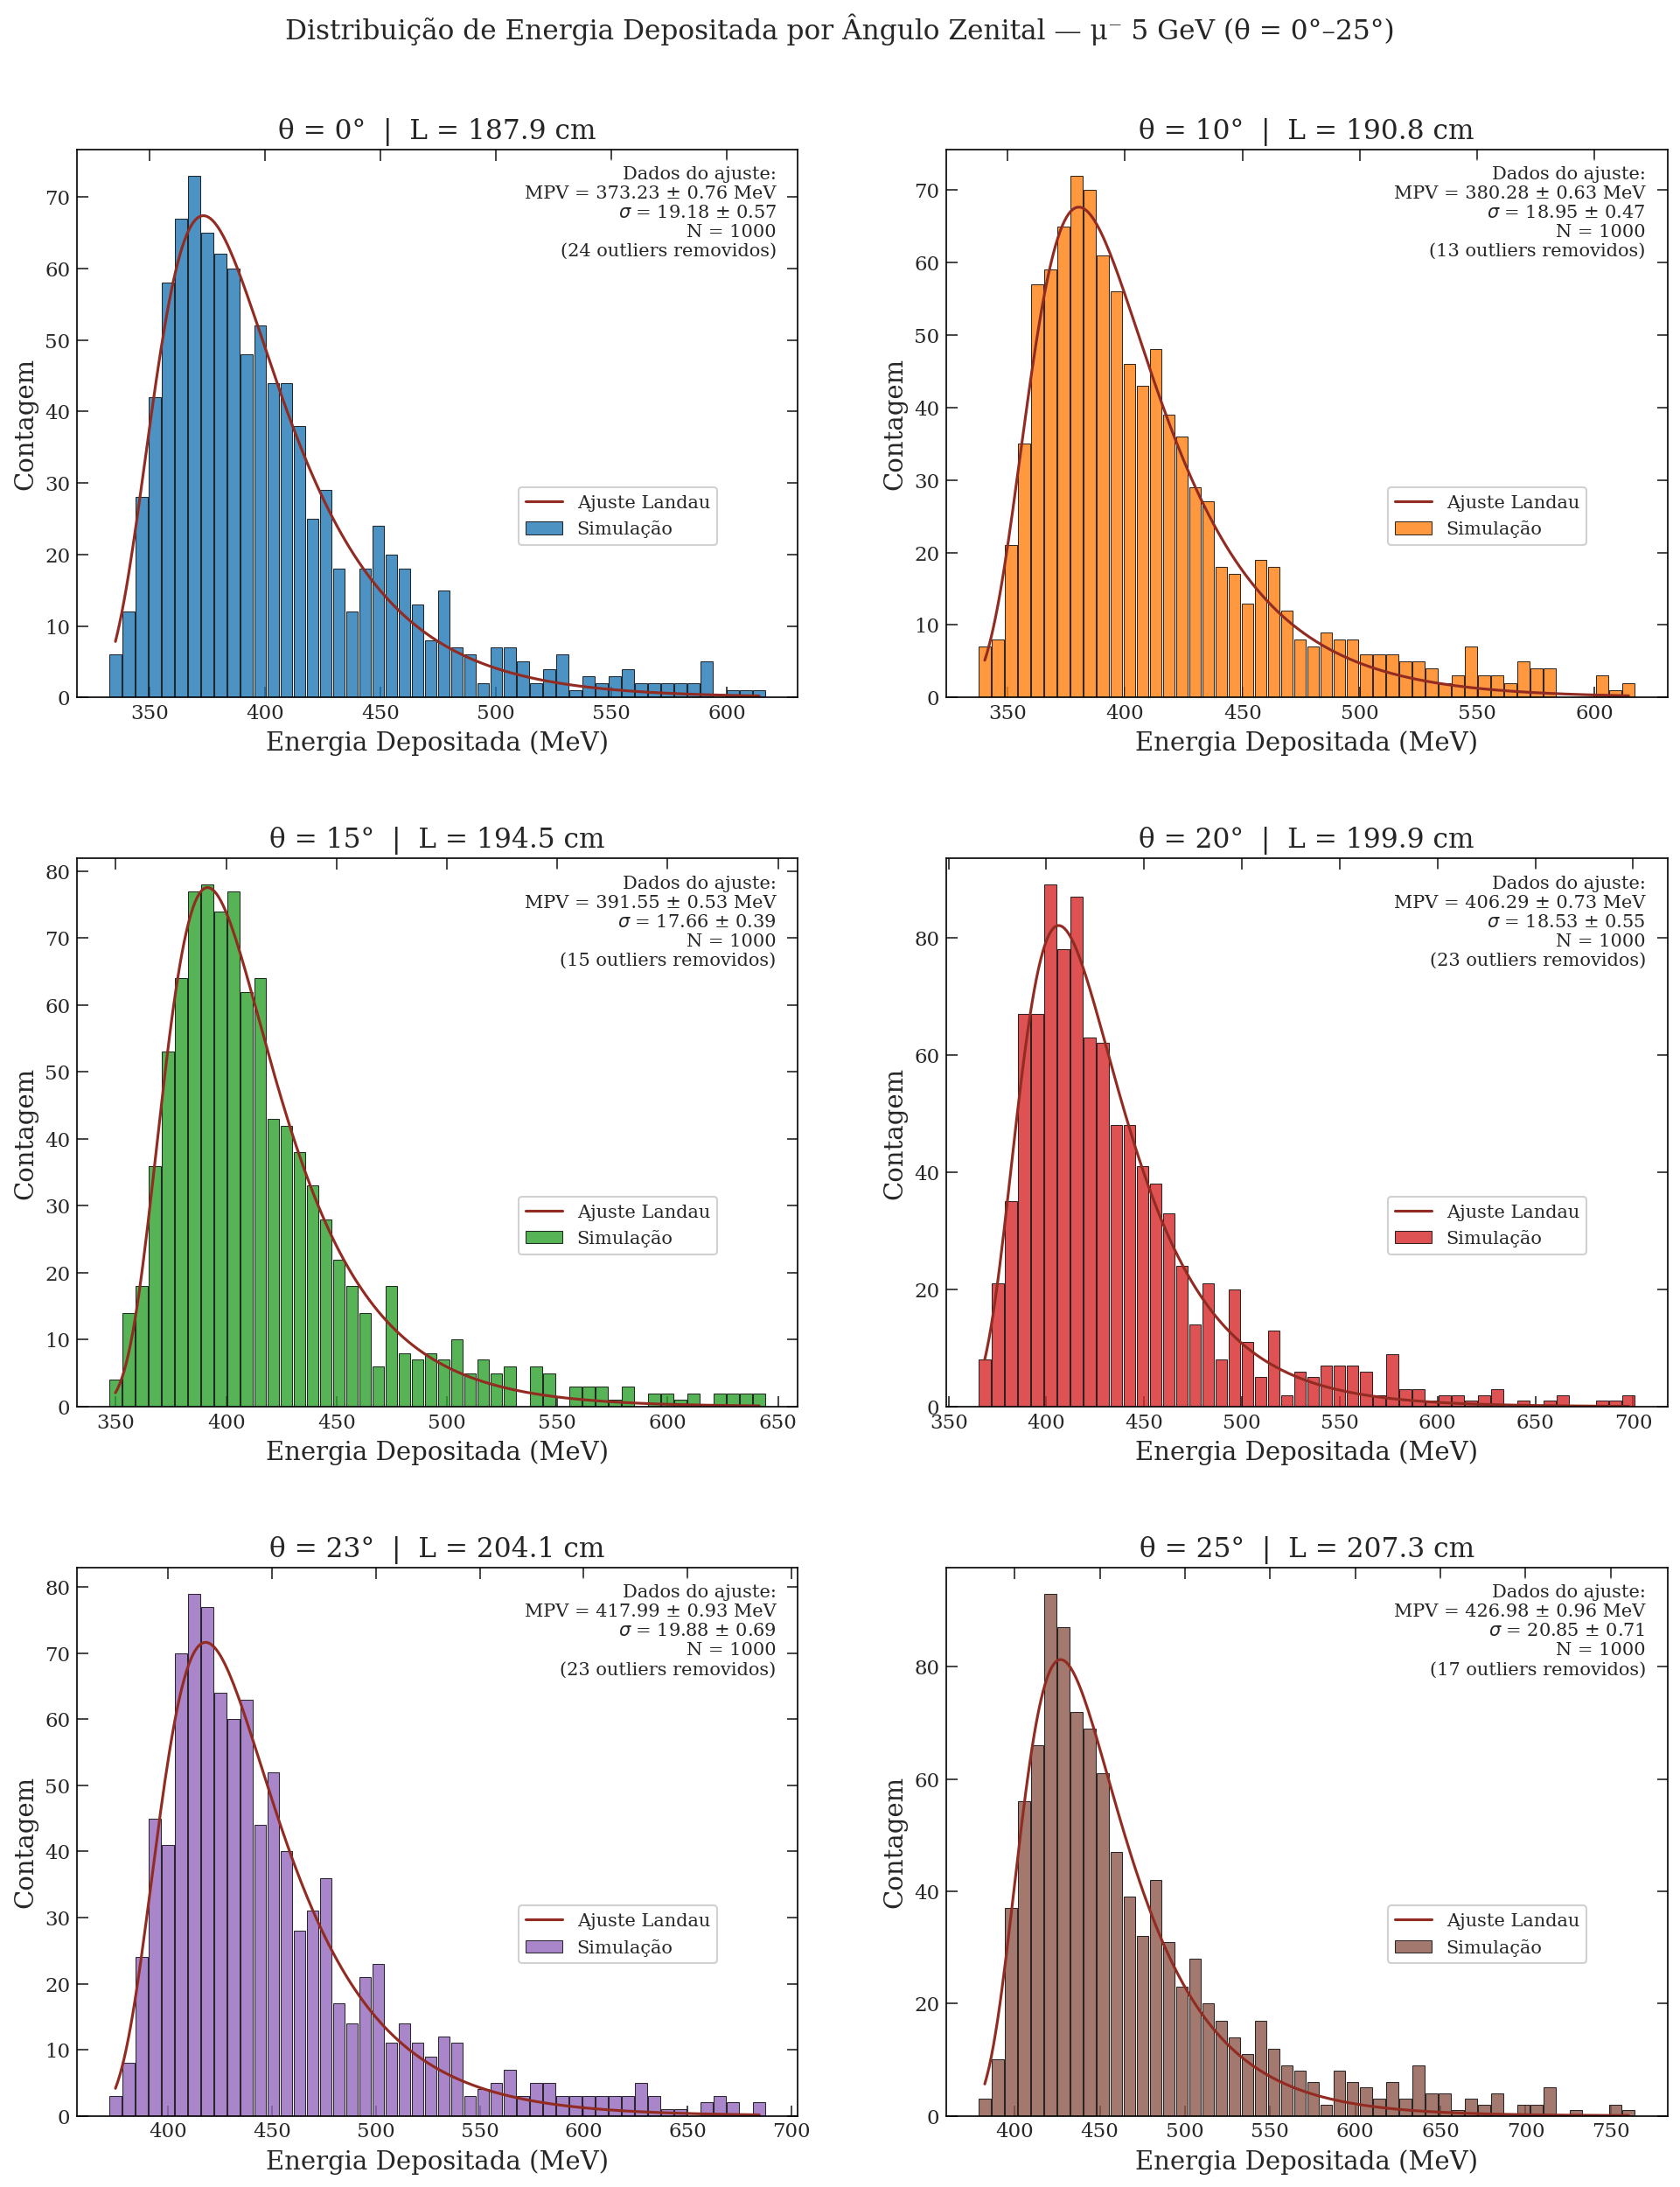

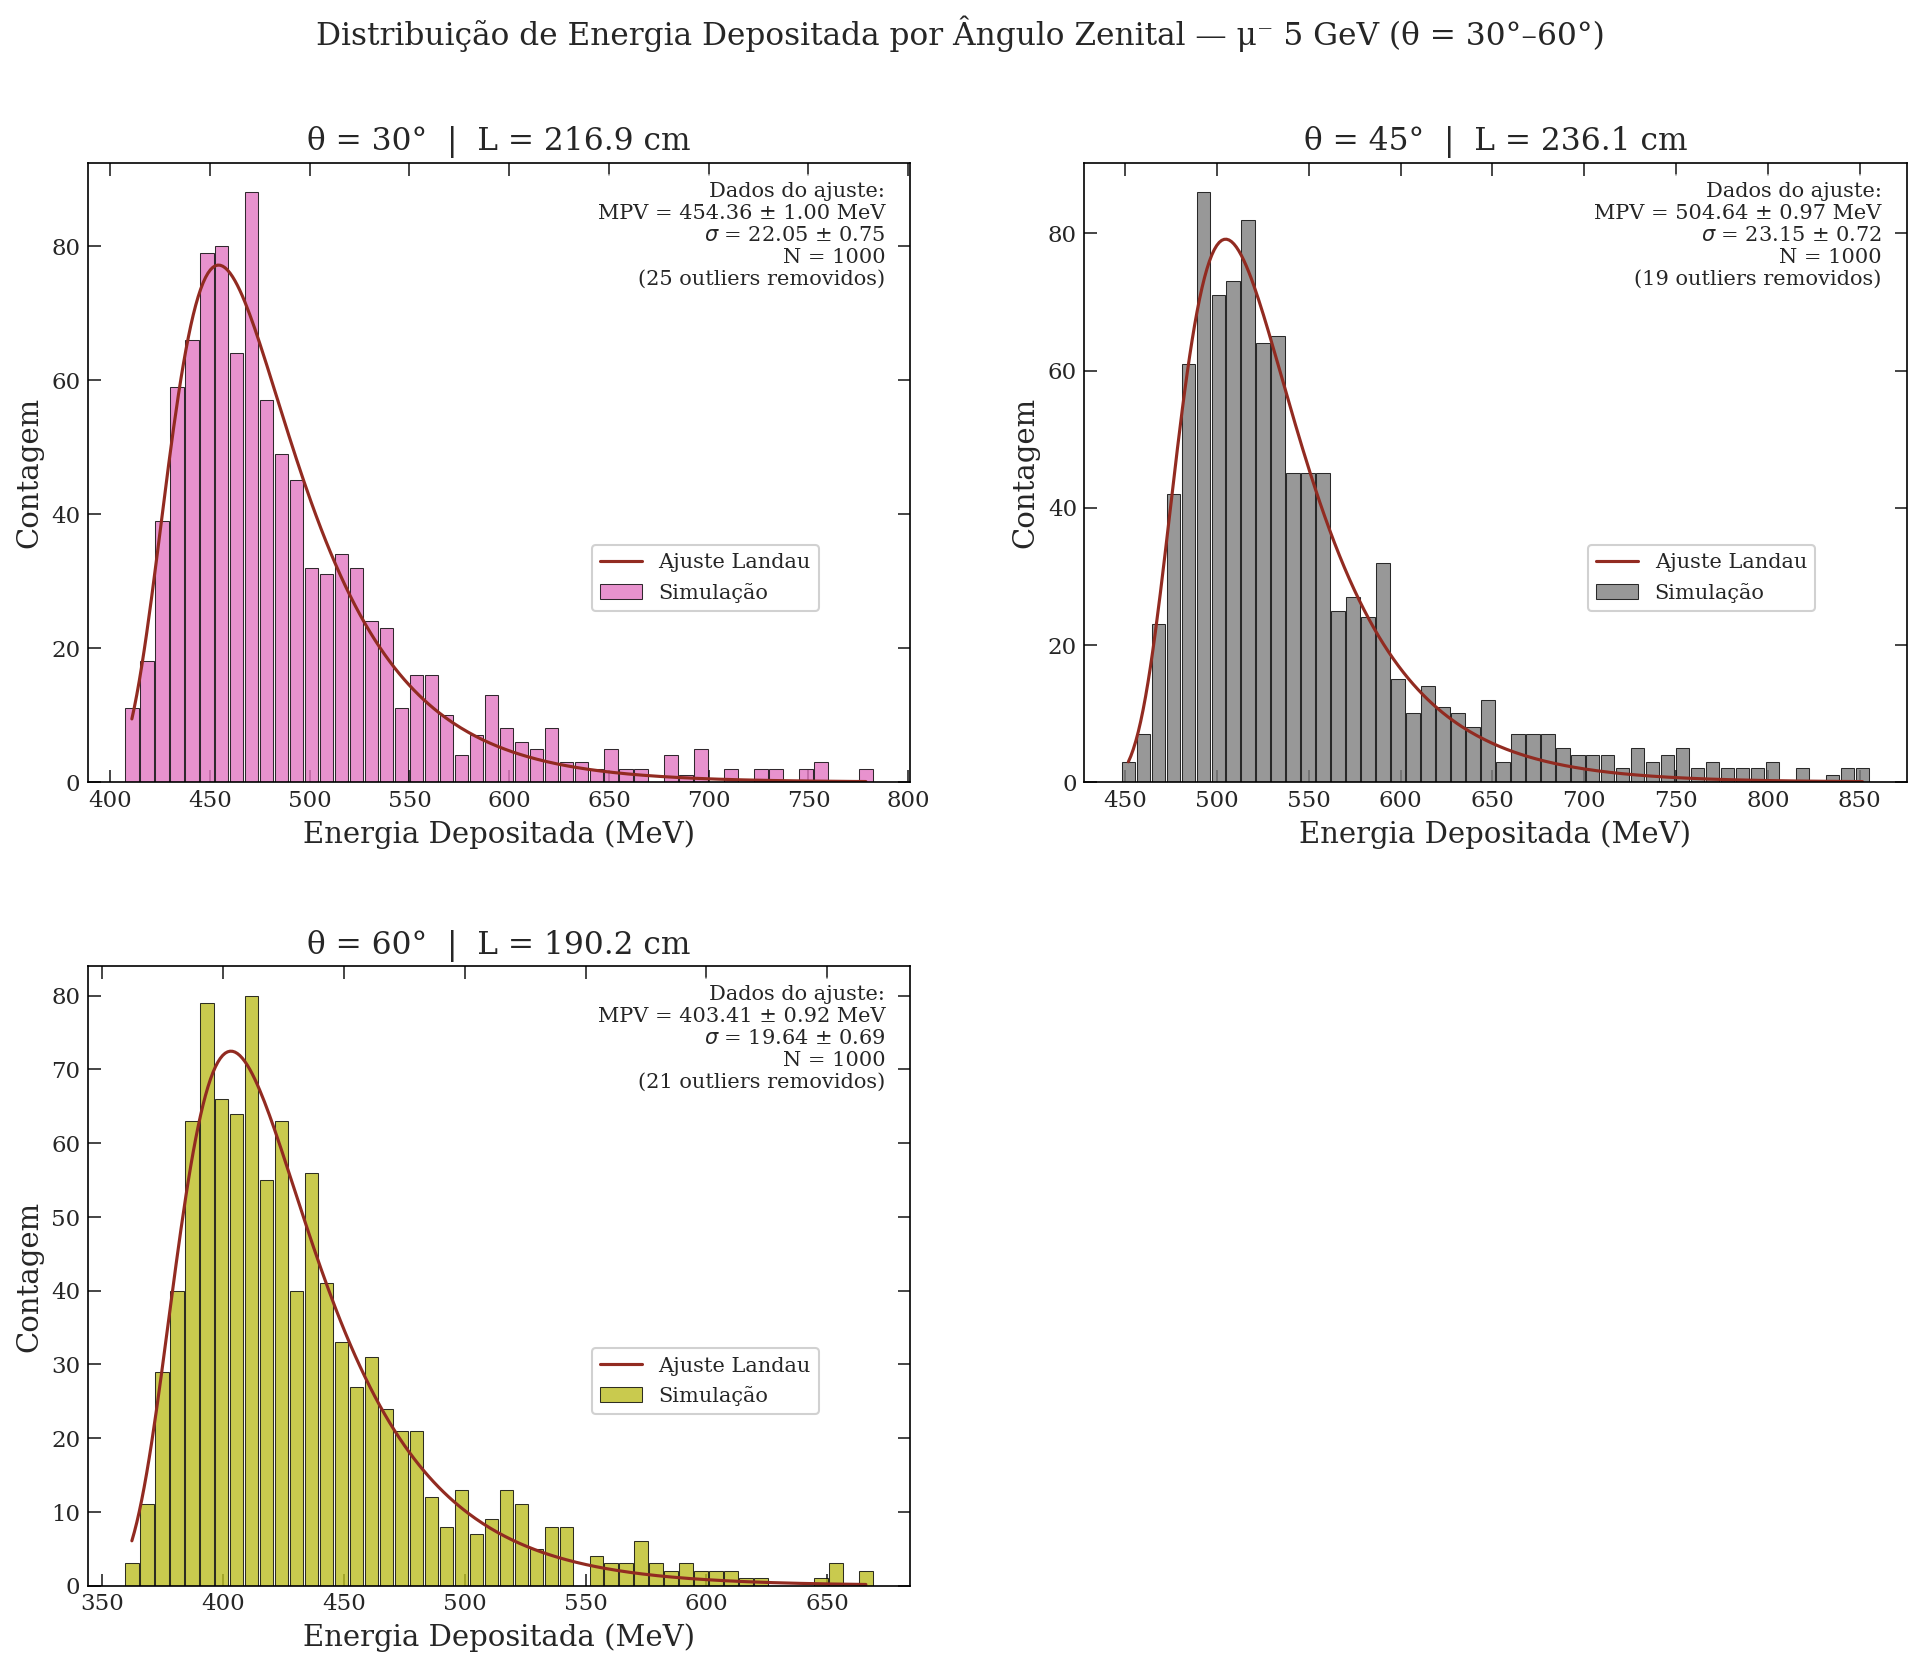

In [5]:
angulos_sorted = sorted(dados.keys())
grupo1 = angulos_sorted[:6]   # primeiros 6 ângulos
grupo2 = angulos_sorted[6:]   # últimos 3 ângulos

def plot_energia(grupo, fname_png, suptitle_extra=''):
    n = len(grupo)
    n_rows = (n + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(13, 5.5 * n_rows))
    axes = axes.flatten()
    for i, ang in enumerate(grupo):
        ax = axes[i]
        edep = dados[ang]['df']['EnergyDeposited_MeV']
        edep_filt = edep[edep < edep.mean() + 3 * edep.std()]
        fit_and_plot(ax, edep_filt, bins=50, color=CORES_ANGULO[ang],
                     fit_func='landau', text_x=0.97, text_y=0.97, text_ha='right',
                     n_total=len(edep), n_filtered=len(edep) - len(edep_filt), unit='MeV')
        ax.set_xlabel('Energia Depositada (MeV)')
        ax.set_ylabel('Contagem')
        ax.set_title(f'θ = {ang}°  |  L = {caminho_por_angulo(ang):.1f} cm')
        ax.legend(fontsize=10, bbox_to_anchor=(0.6, 0.4), loc='upper left')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Distribuição de Energia Depositada por Ângulo Zenital — μ⁻ 5 GeV{suptitle_extra}',
                 fontsize=15, y=1.01)
    plt.tight_layout(h_pad=3, w_pad=3)
    plt.savefig(fname_png, dpi=300, bbox_inches='tight')
    plt.show()

plot_energia(grupo1, 'angular_energia_depositada_1.png', ' (θ = 0°–25°)')
plot_energia(grupo2, 'angular_energia_depositada_2.png', ' (θ = 30°–60°)')


## 6. Distribuições por Ângulo — Fótons Detectados pelas PMTs

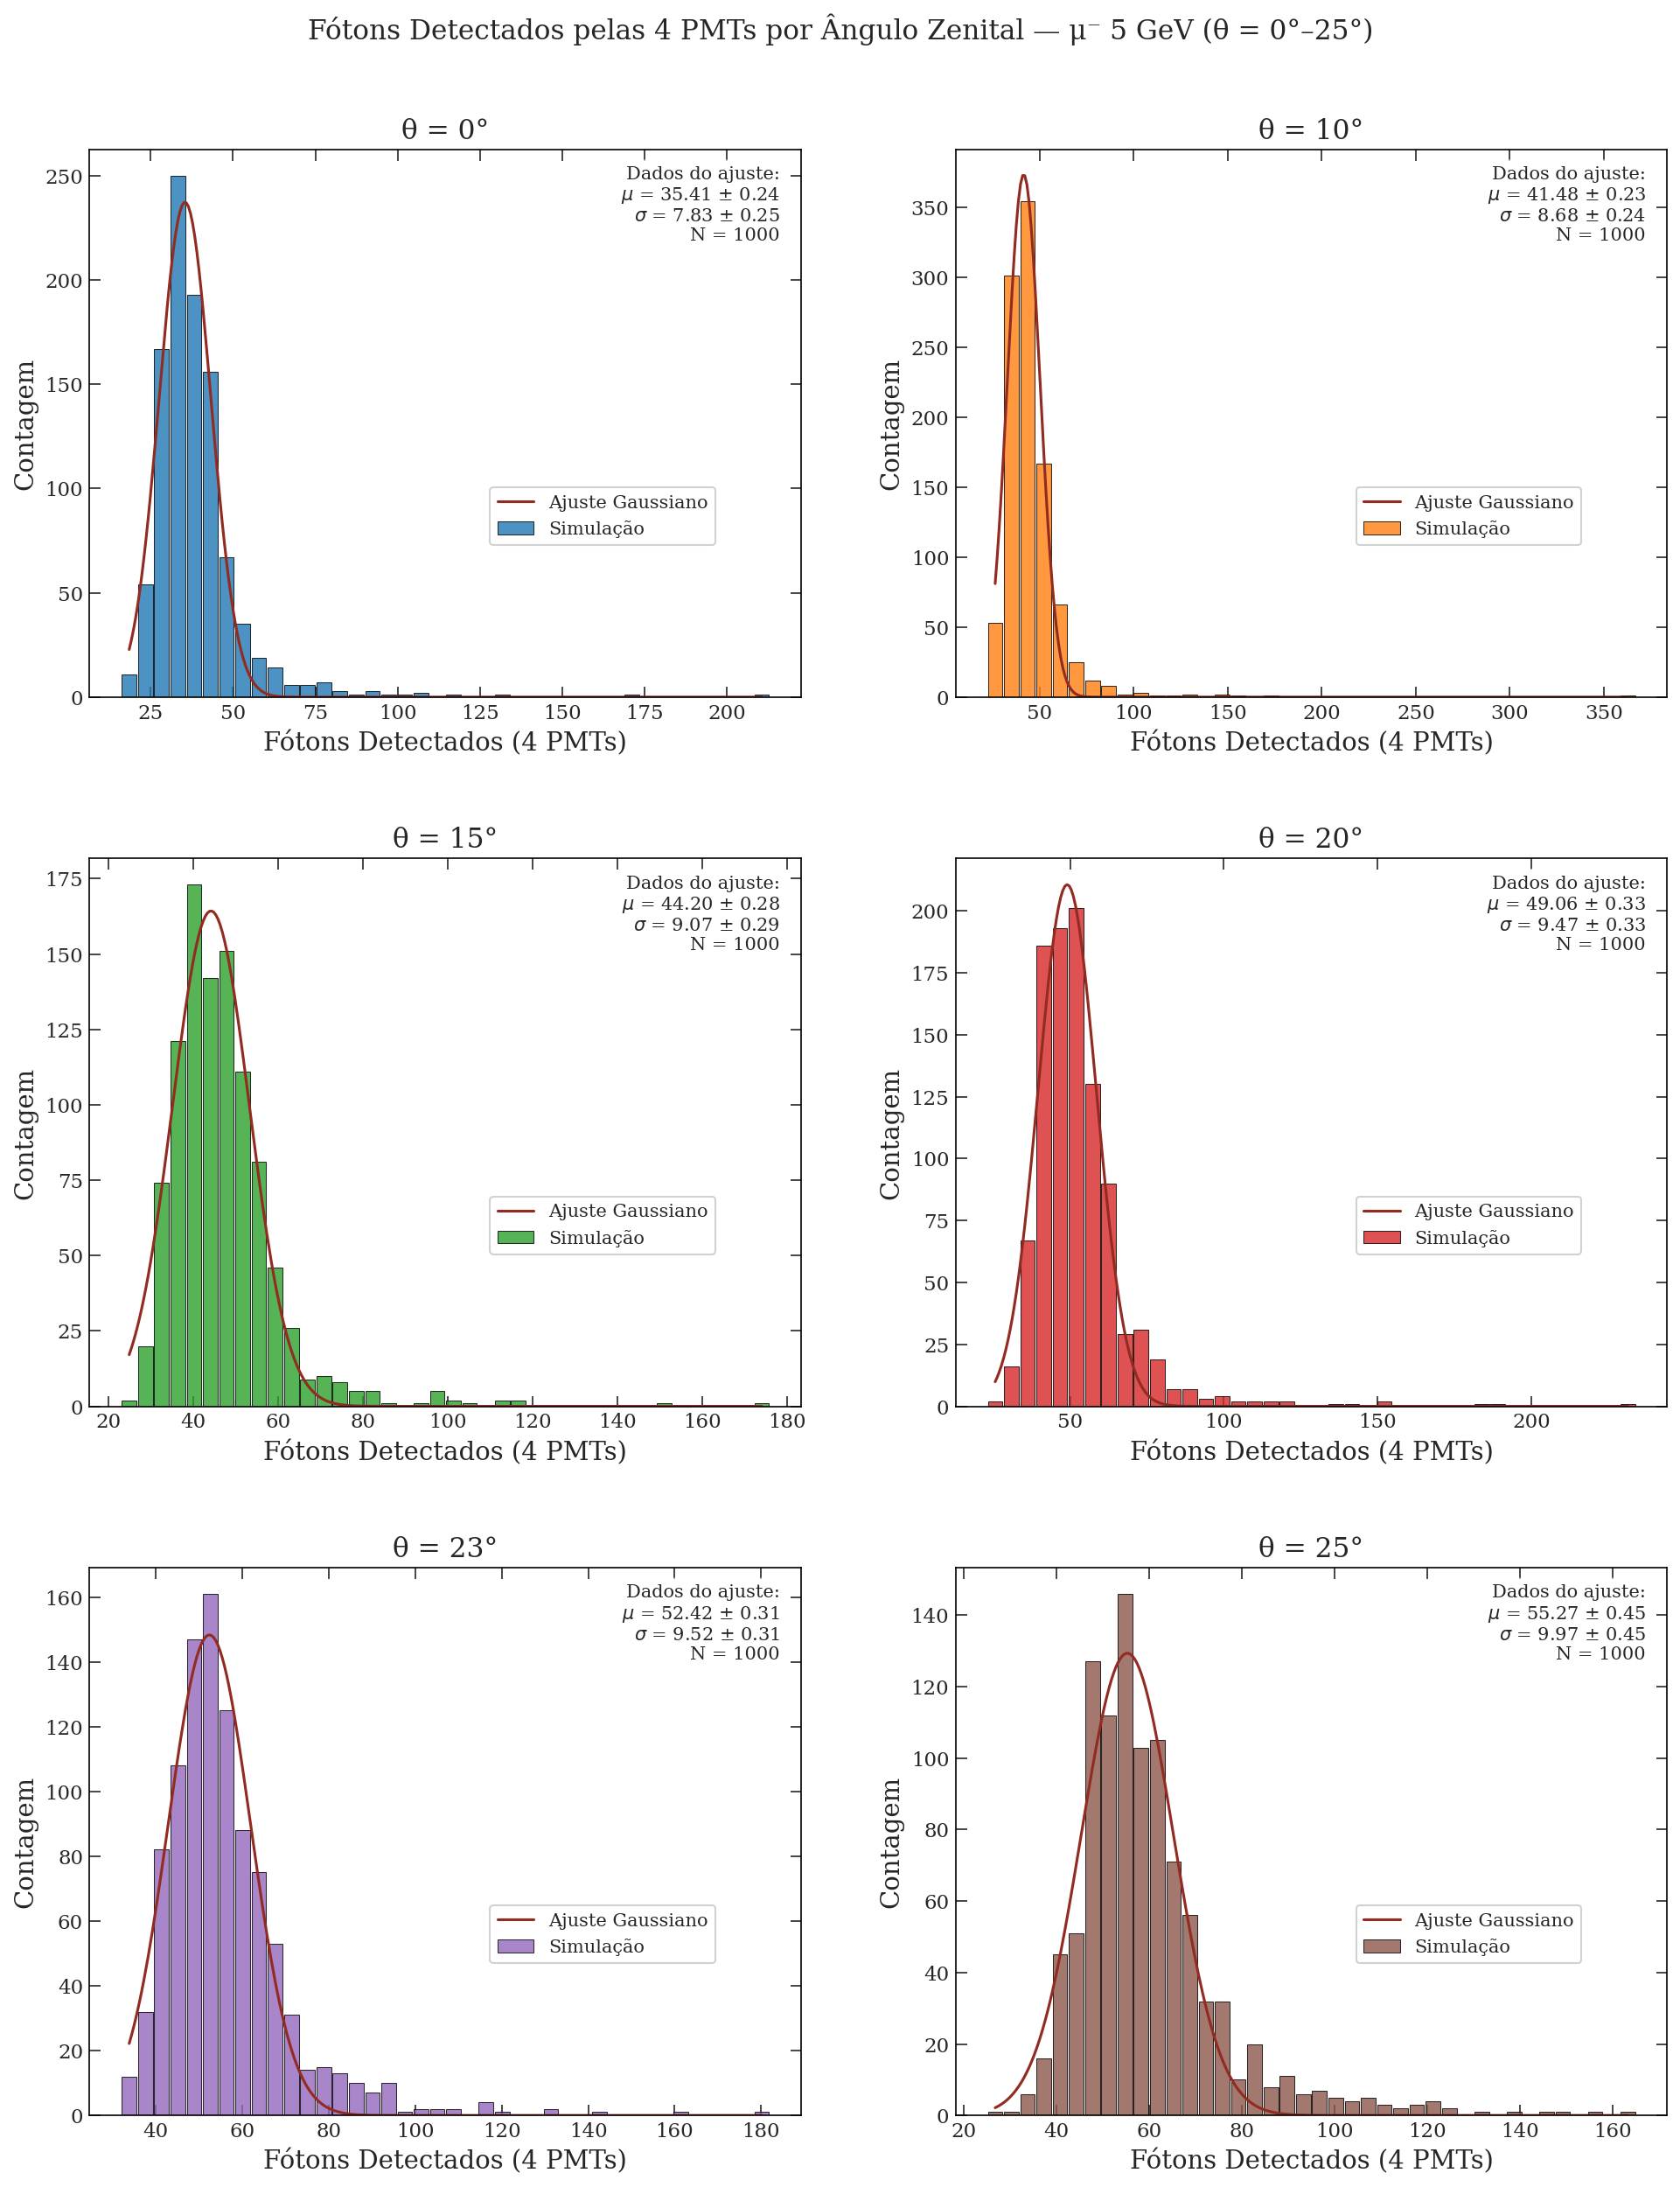

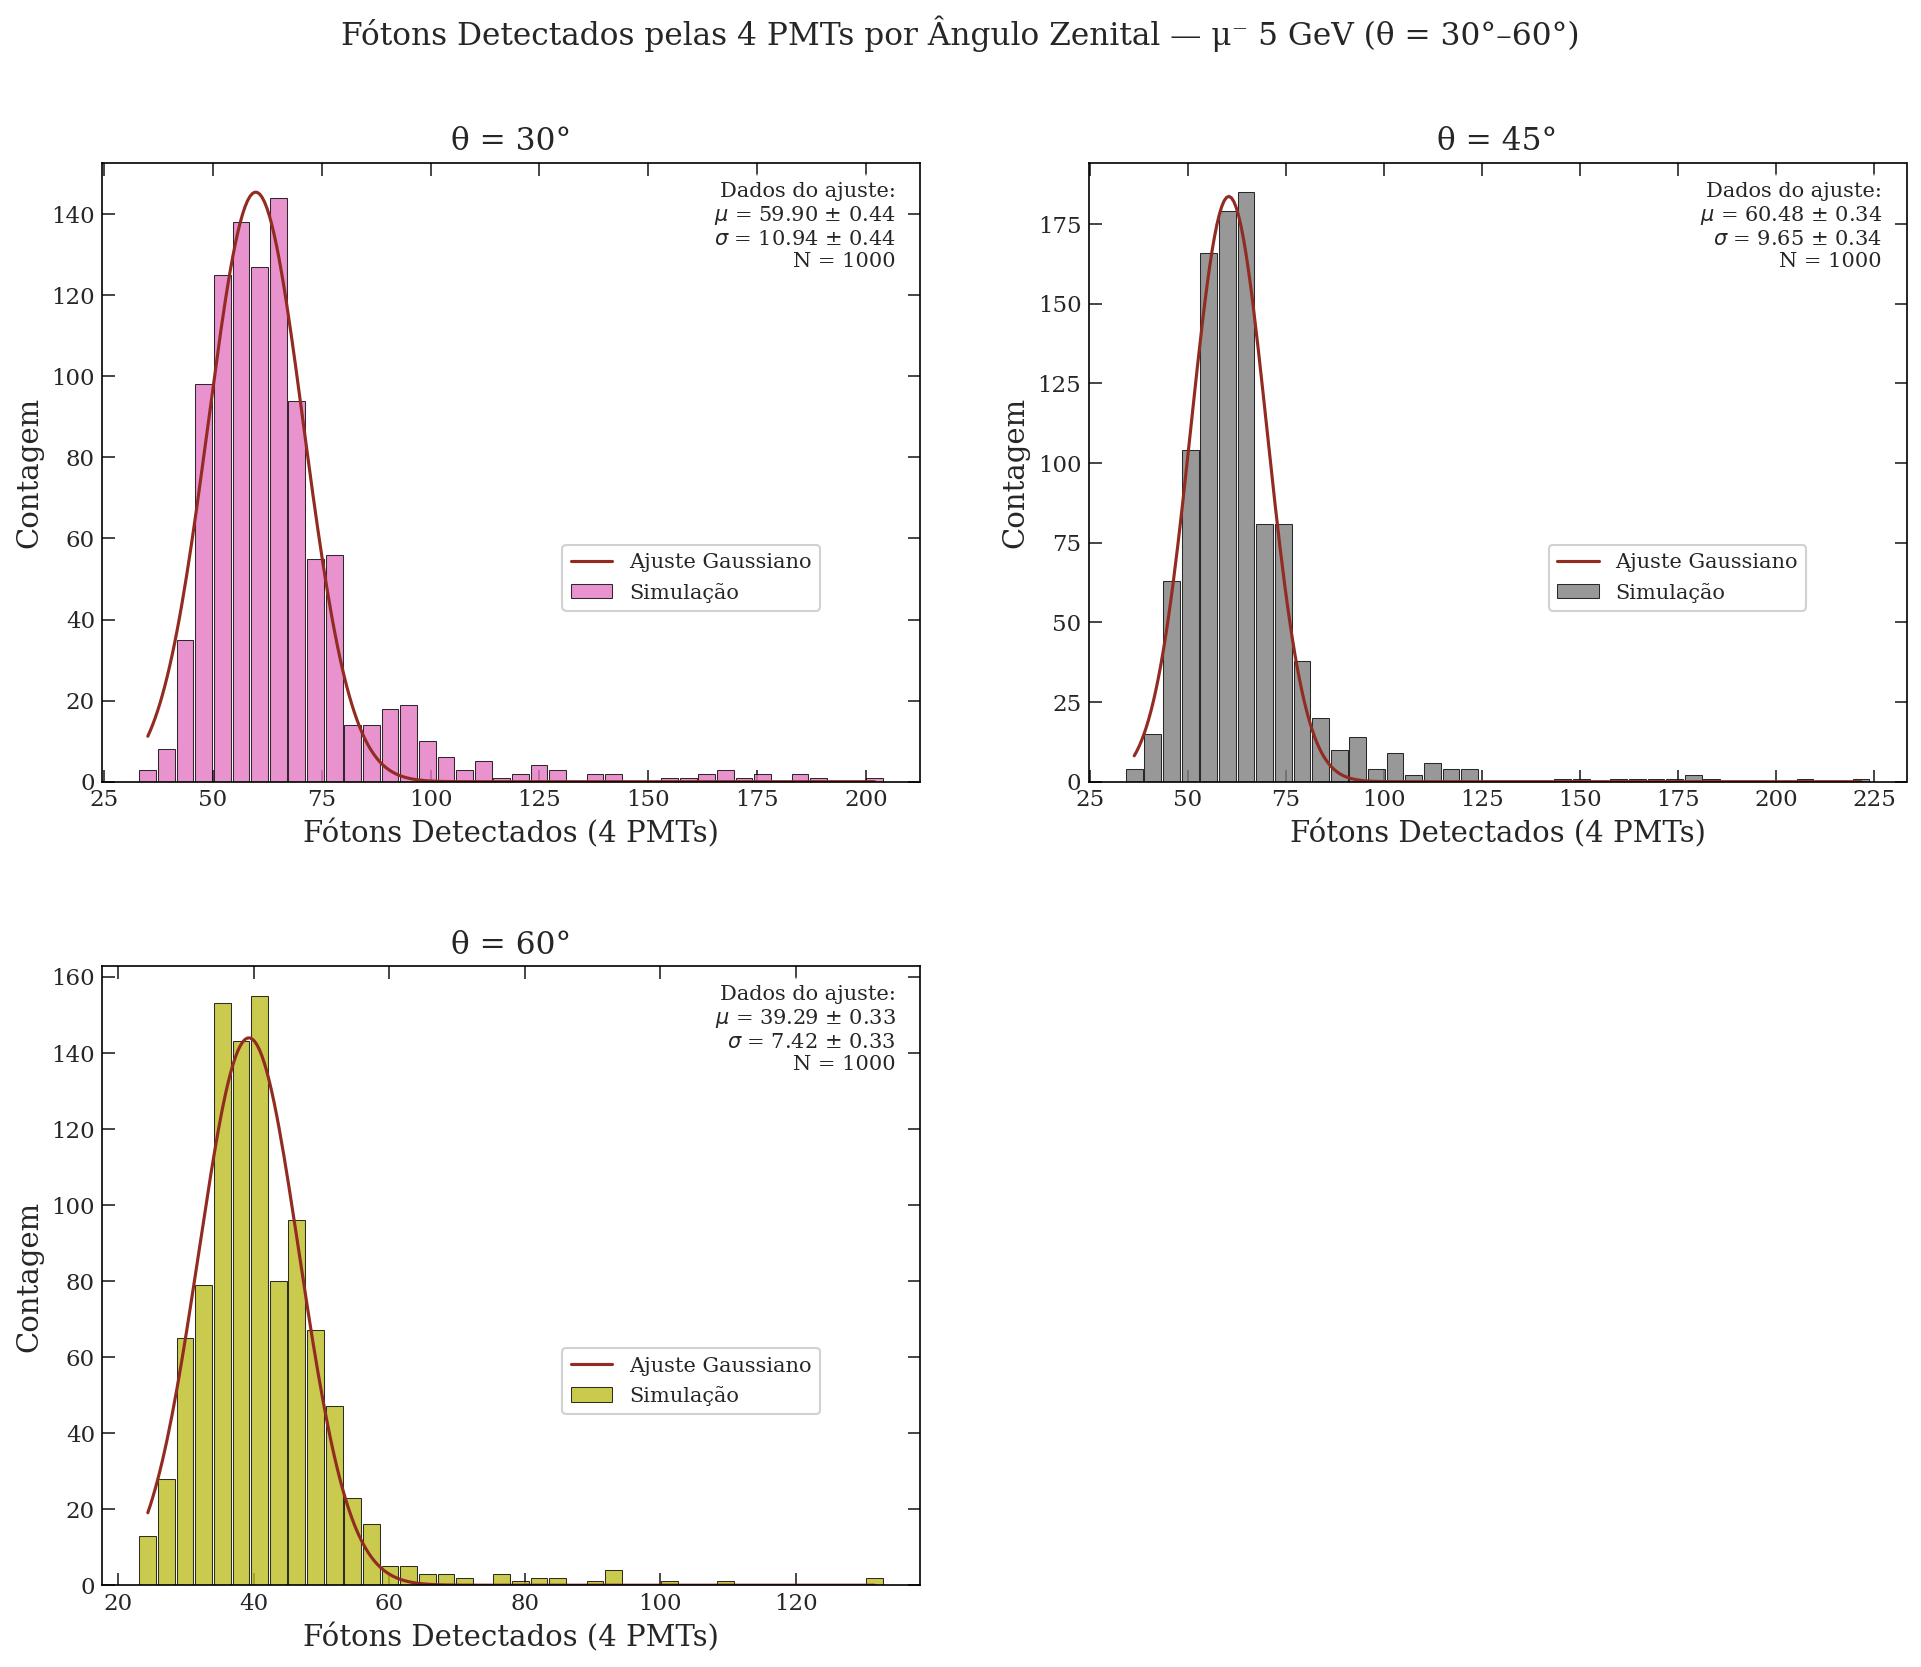

In [6]:
def plot_fotons_pmt(grupo, fname_png, suptitle_extra=''):
    n = len(grupo)
    n_rows = (n + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(13, 5.5 * n_rows))
    axes = axes.flatten()
    for i, ang in enumerate(grupo):
        ax = axes[i]
        total = dados[ang]['df_pmt']['nFotonsTotal']
        fit_and_plot(ax, total, bins=40, color=CORES_ANGULO[ang],
                     fit_func='gaussian', text_x=0.97, text_y=0.97, text_ha='right')
        ax.set_xlabel('Fótons Detectados (4 PMTs)')
        ax.set_ylabel('Contagem')
        ax.set_title(f'θ = {ang}°')
        ax.legend(fontsize=10, bbox_to_anchor=(0.55, 0.4), loc='upper left')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Fótons Detectados pelas 4 PMTs por Ângulo Zenital — μ⁻ 5 GeV{suptitle_extra}',
                 fontsize=15, y=1.01)
    plt.tight_layout(h_pad=3, w_pad=3)
    plt.savefig(fname_png, dpi=300, bbox_inches='tight')
    plt.show()

plot_fotons_pmt(grupo1, 'angular_fotons_pmt_1.png', ' (θ = 0°–25°)')
plot_fotons_pmt(grupo2, 'angular_fotons_pmt_2.png', ' (θ = 30°–60°)')


## 7. Evolução das Grandezas com o Ângulo (Plots Comparativos)

Aqui comparamos todas as grandezas físicas em função de θ para verificar a consistência.

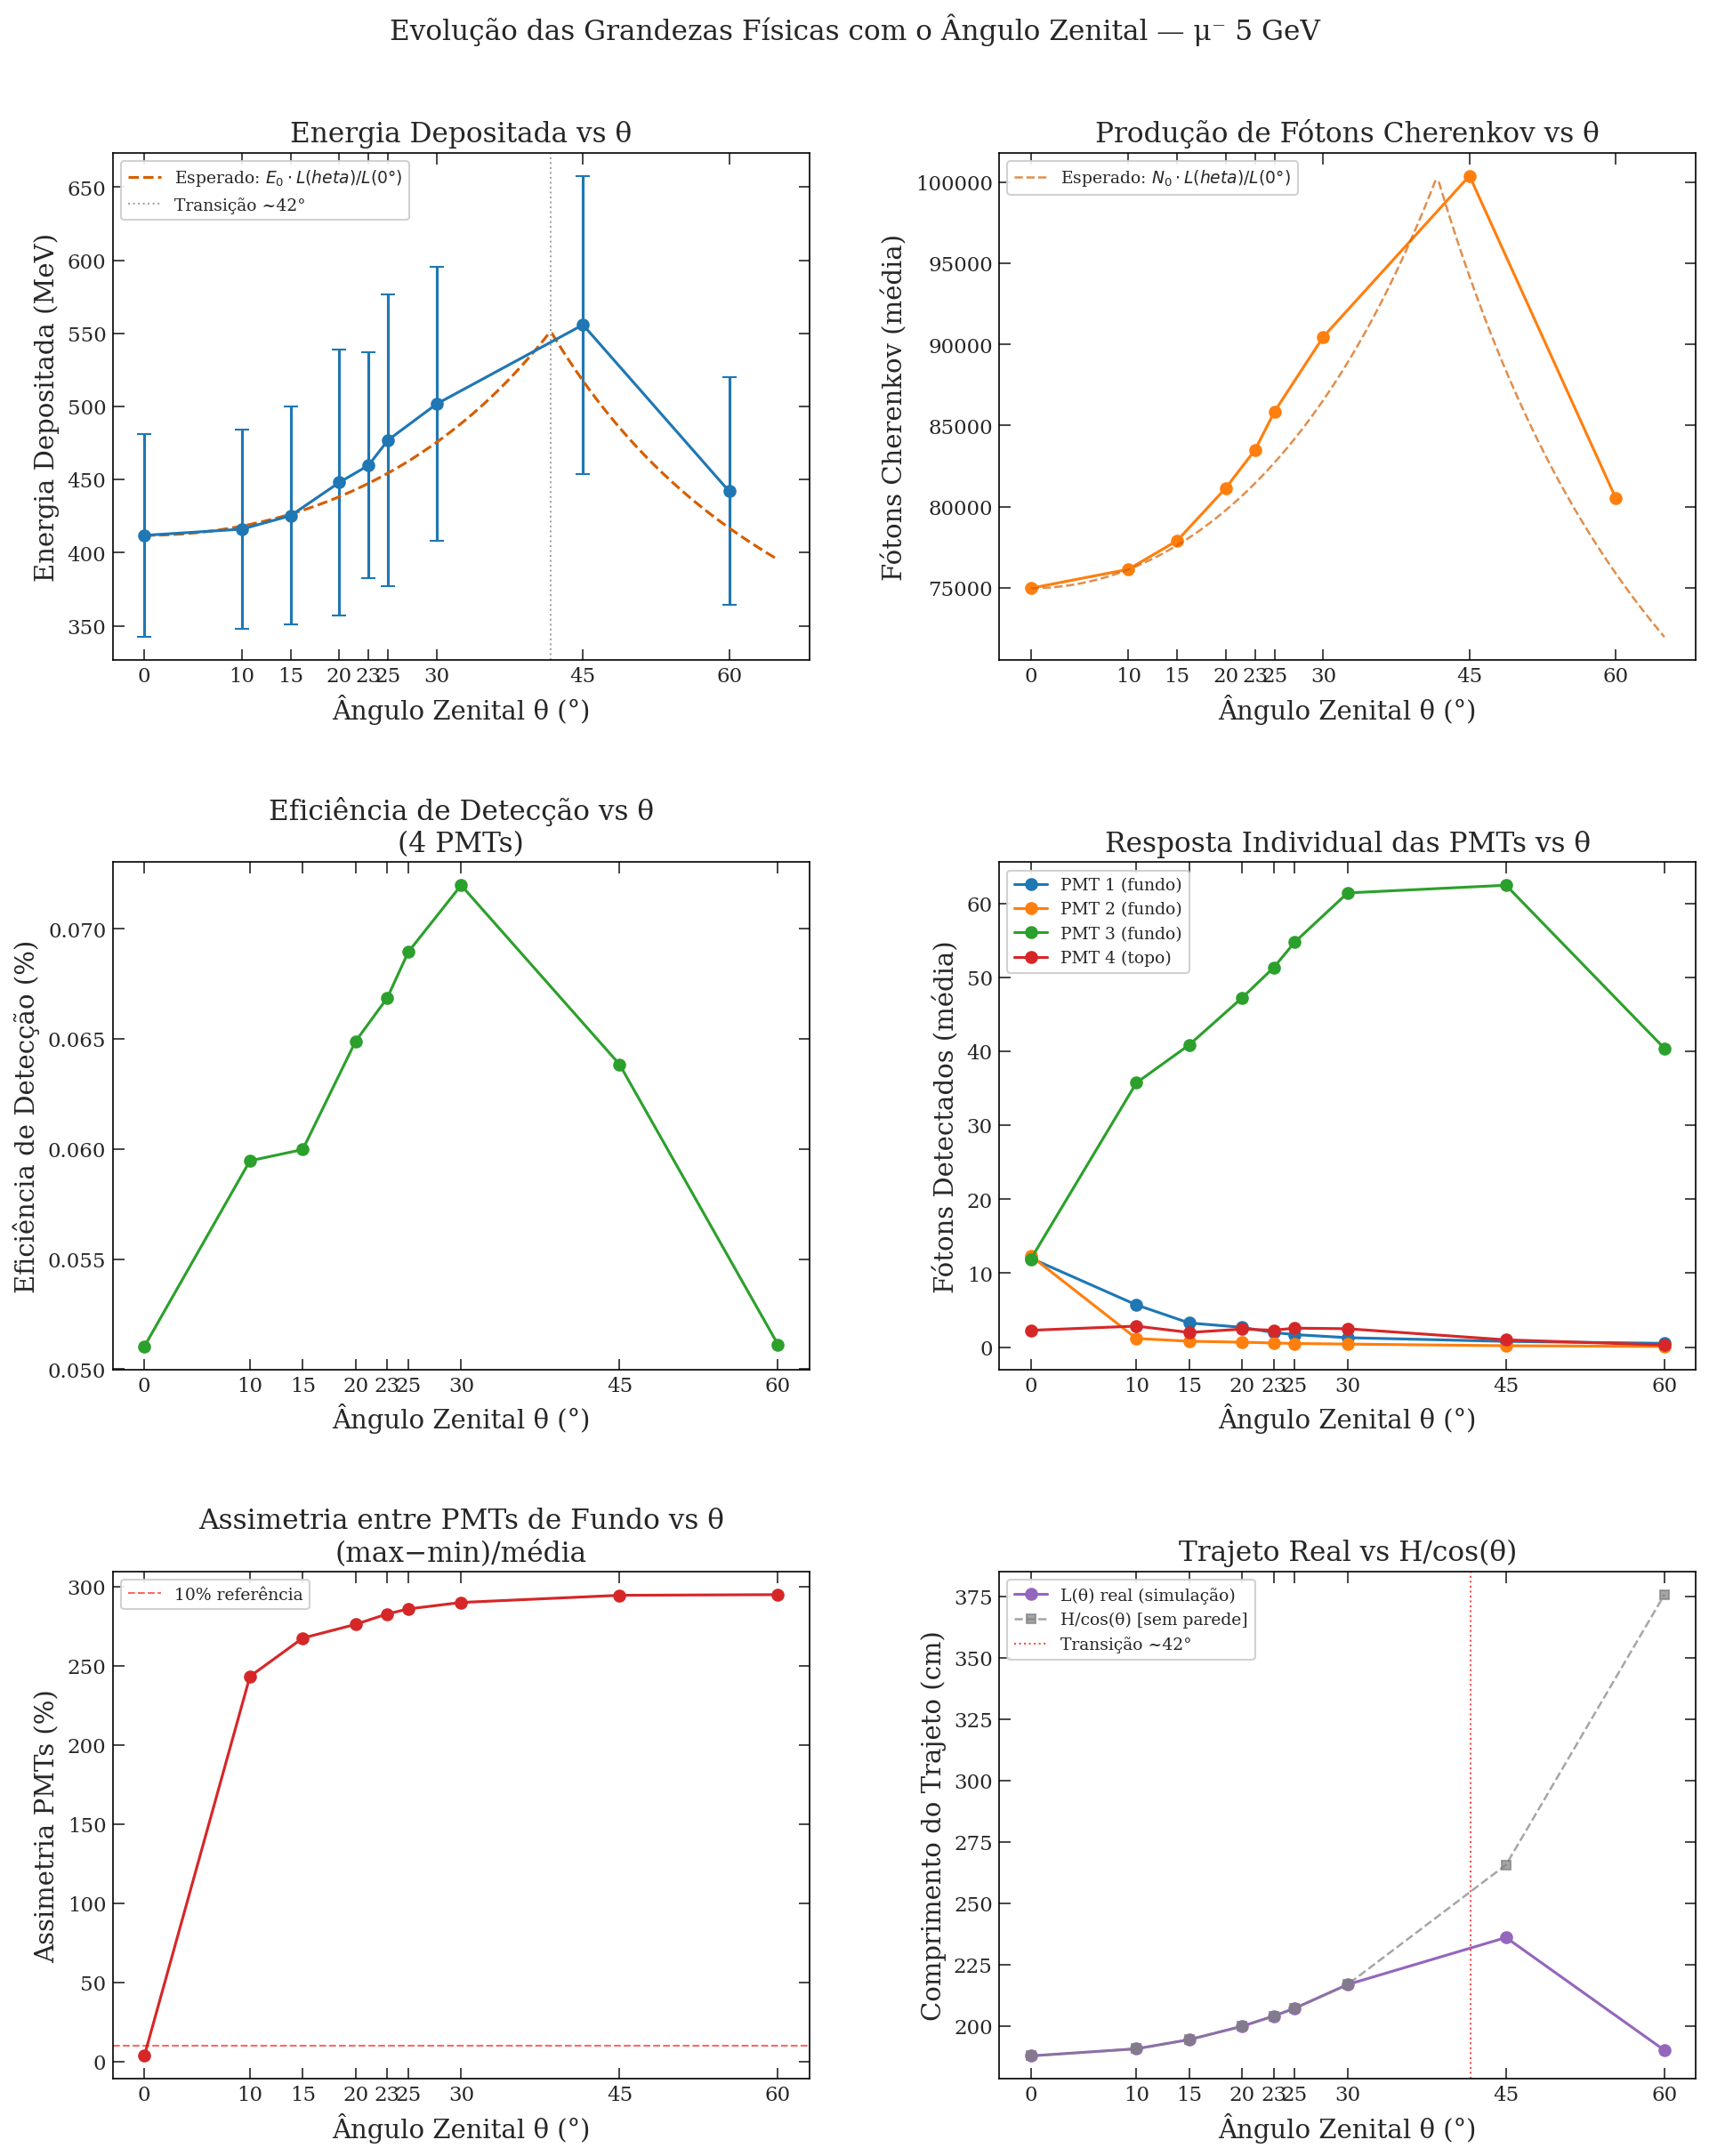

In [7]:
df_res = df_resumo.set_index('angulo')
angulos_list = sorted(dados.keys())
cores_list = [CORES_ANGULO[a] for a in angulos_list]

fig, axes = plt.subplots(3, 2, figsize=(13, 16))

# ── 1. Energia depositada vs θ ─────────────────────────────────────────────
ax = axes[0, 0]
ax.errorbar(angulos_list, df_res.loc[angulos_list, 'edep_mean'],
            yerr=df_res.loc[angulos_list, 'edep_std'],
            fmt='o-', color=palette[0], capsize=4, linewidth=1.5, markersize=6)

# Curva teórica corrigida: E0 * L(theta) / L(0)
edep0 = df_res.loc[0, 'edep_mean'] if 0 in df_res.index else None
if edep0:
    theta_th = np.linspace(0, 65, 200)
    L0 = caminho_por_angulo(0)
    L_th = [caminho_por_angulo(t) for t in theta_th]
    edep_th = [edep0 * L / L0 for L in L_th]
    ax.plot(theta_th, edep_th, 'r--', linewidth=1.5,
            label='Esperado: $E_0 \cdot L(\theta)/L(0°)$')
    # Marca o ângulo de transição
    theta_trans = np.degrees(np.arctan(170.0 / (97.0 - 187.87/2 + 187.87)))
    ax.axvline(x=theta_trans, color='gray', linestyle=':', linewidth=1,
               alpha=0.7, label=f'Transição ~{theta_trans:.0f}°')
    ax.legend(fontsize=9)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Energia Depositada (MeV)')
ax.set_title('Energia Depositada vs θ')
ax.set_xticks(angulos_list)

# ── 2. Fótons Cherenkov totais vs θ ────────────────────────────────────────
ax = axes[0, 1]
ax.plot(angulos_list, df_res.loc[angulos_list, 'cer_mean'],
        'o-', color=palette[1], linewidth=1.5, markersize=6)
# Curva teórica corrigida
if 0 in df_res.index:
    cer0 = df_res.loc[0, 'cer_mean']
    cer_th = [cer0 * caminho_por_angulo(t) / L0 for t in theta_th]
    ax.plot(theta_th, cer_th, 'r--', linewidth=1.2, alpha=0.7,
            label='Esperado: $N_0 \cdot L(\theta)/L(0°)$')
    ax.legend(fontsize=9)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Fótons Cherenkov (média)')
ax.set_title('Produção de Fótons Cherenkov vs θ')
ax.set_xticks(angulos_list)

# ── 3. Eficiência de detecção vs θ ─────────────────────────────────────────
ax = axes[1, 0]
ax.plot(angulos_list, df_res.loc[angulos_list, 'ef_mean'],
        'o-', color=palette[2], linewidth=1.5, markersize=6)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Eficiência de Detecção (%)')
ax.set_title('Eficiência de Detecção vs θ\n(4 PMTs)')
ax.set_xticks(angulos_list)

# ── 4. Resposta por PMT vs θ ────────────────────────────────────────────────
ax = axes[1, 1]
for pmt_col, cor, lbl in zip(
        ['pmt1_mean', 'pmt2_mean', 'pmt3_mean', 'pmt4_mean'],
        [palette[0], palette[1], palette[2], palette[3]],
        ['PMT 1 (fundo)', 'PMT 2 (fundo)', 'PMT 3 (fundo)', 'PMT 4 (topo)']):
    ax.plot(angulos_list, df_res.loc[angulos_list, pmt_col],
            'o-', color=cor, linewidth=1.5, markersize=6, label=lbl)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Fótons Detectados (média)')
ax.set_title('Resposta Individual das PMTs vs θ')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

# ── 5. Assimetria entre PMTs do fundo vs θ ────────────────────────────────
ax = axes[2, 0]
pmt_vals = df_res.loc[angulos_list, ['pmt1_mean', 'pmt2_mean', 'pmt3_mean']].values
pmt_max = pmt_vals.max(axis=1)
pmt_min = pmt_vals.min(axis=1)
pmt_mean_row = pmt_vals.mean(axis=1)
assimetria = (pmt_max - pmt_min) / pmt_mean_row * 100
ax.plot(angulos_list, assimetria, 'o-', color=palette[3], linewidth=1.5, markersize=6)
ax.axhline(y=10, color='red', linestyle='--', linewidth=1, alpha=0.6, label='10% referência')
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Assimetria PMTs (%)')
ax.set_title('Assimetria entre PMTs de Fundo vs θ\n(max−min)/média')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

# ── 6. Comprimento do trajeto real vs 1/cos(θ) ────────────────────────────
ax = axes[2, 1]
L_vals_real = [caminho_por_angulo(a) for a in angulos_list]
L_vals_costh = [187.87 / np.cos(np.radians(a)) for a in angulos_list]

ax.plot(angulos_list, L_vals_real,  'o-', color=palette[4], linewidth=1.5,
        markersize=6, label='L(θ) real (simulação)')
ax.plot(angulos_list, L_vals_costh, 's--', color='gray', linewidth=1.2,
        markersize=5, alpha=0.7, label='H/cos(θ) [sem parede]')
ax.axvline(x=theta_trans, color='red', linestyle=':', linewidth=1,
           alpha=0.7, label=f'Transição ~{theta_trans:.0f}°')
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Comprimento do Trajeto (cm)')
ax.set_title('Trajeto Real vs H/cos(θ)')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

plt.suptitle('Evolução das Grandezas Físicas com o Ângulo Zenital — μ⁻ 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('angular_evolucao_grandezas.png', dpi=300, bbox_inches='tight')
plt.show()


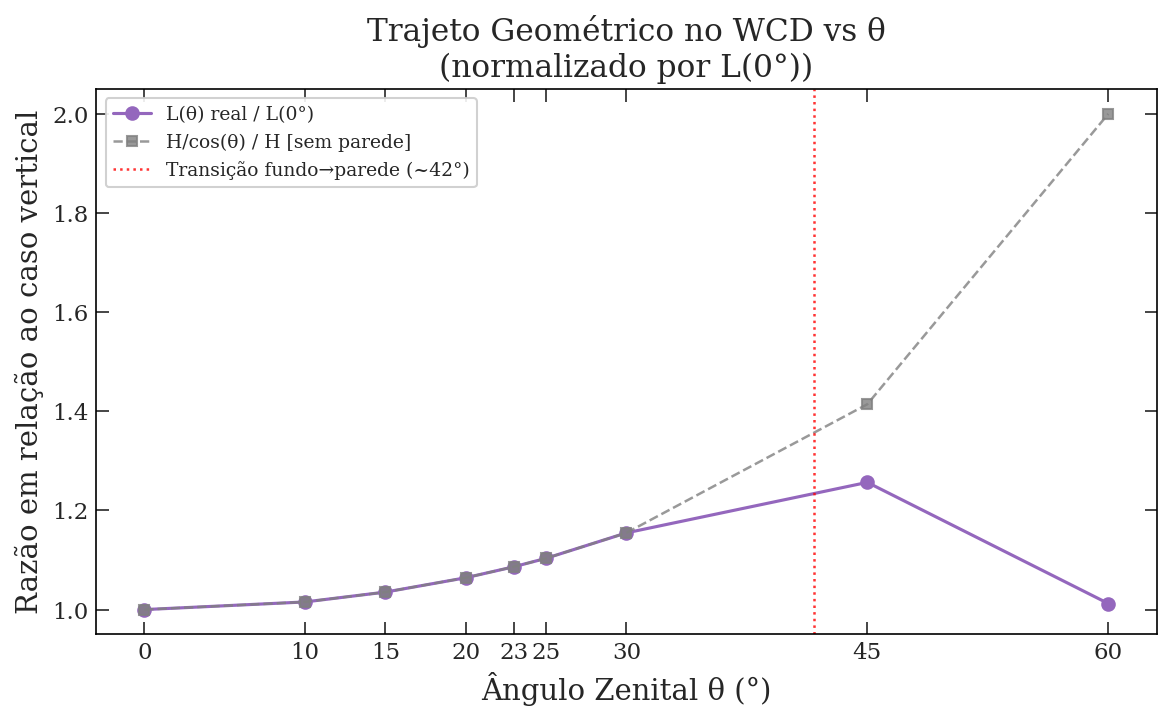

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

L_vals_real  = [caminho_por_angulo(a) for a in angulos_list]
L_vals_costh = [187.87 / np.cos(np.radians(a)) for a in angulos_list]
L0 = caminho_por_angulo(0)

L_real_norm  = [L / L0 for L in L_vals_real]
L_costh_norm = [L / L0 for L in L_vals_costh]

ax.plot(angulos_list, L_real_norm,  'o-',  color=palette[4], linewidth=1.5,
        markersize=6, label='L(θ) real / L(0°)')
ax.plot(angulos_list, L_costh_norm, 's--', color='gray', linewidth=1.2,
        markersize=5, alpha=0.8, label='H/cos(θ) / H [sem parede]')
ax.axvline(x=theta_trans, color='red', linestyle=':', linewidth=1.2,
           alpha=0.8, label=f'Transição fundo→parede (~{theta_trans:.0f}°)')

ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Razão em relação ao caso vertical')
ax.set_title('Trajeto Geométrico no WCD vs θ\n(normalizado por L(0°))')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

plt.tight_layout()
#plt.savefig('angular_trajeto_geometrico.png', dpi=300, bbox_inches='tight')
#plt.show()


## 8. Sobreposição das Distribuições — Comparação Direta

Todas as distribuições de energia depositada sobrepostas no mesmo plot para comparação visual.

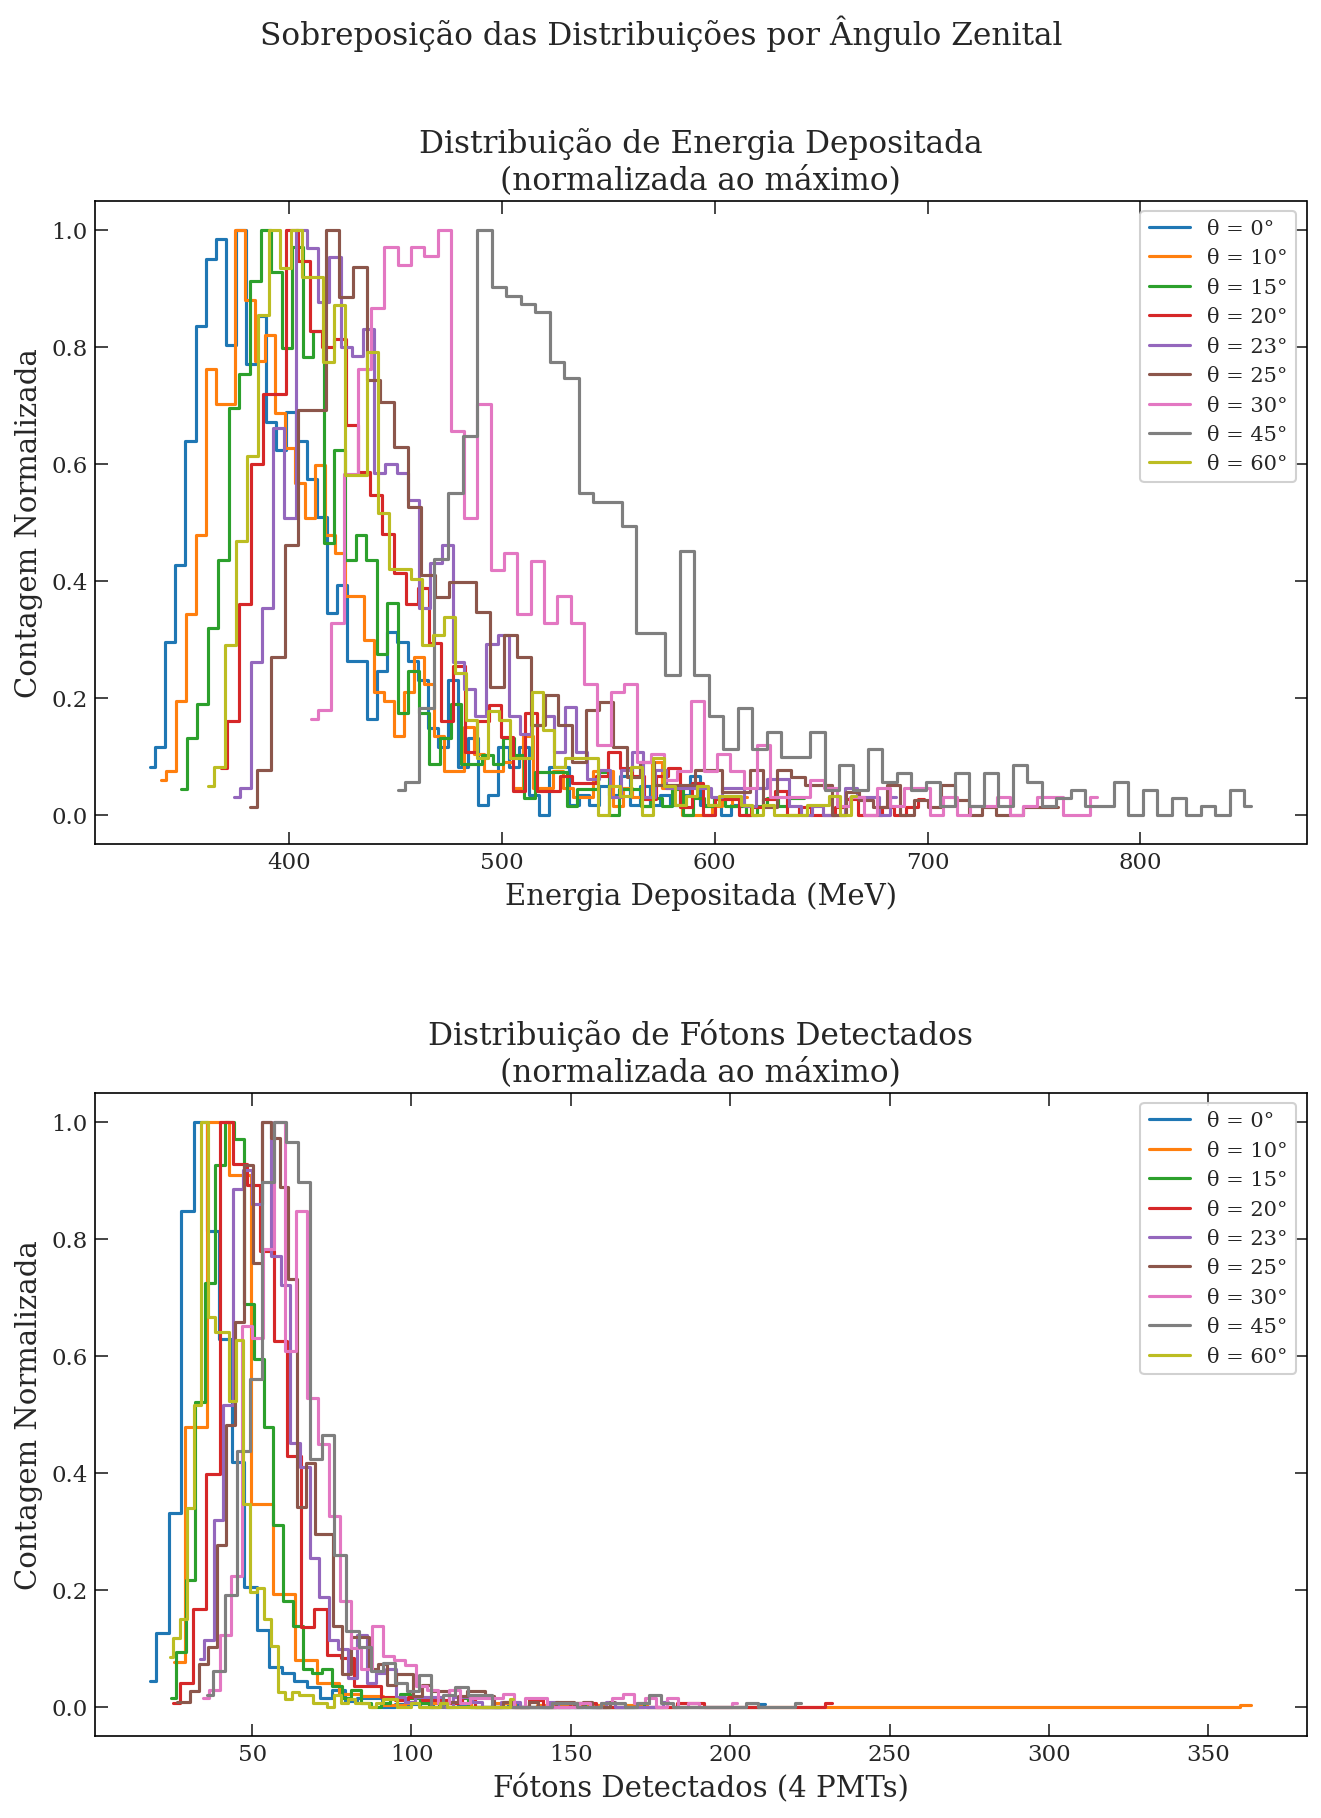

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 12))

# ── Energia depositada — sobreposição ──────────────────────────────────────
ax1 = axes[0]
for ang in angulos_list:
    edep = dados[ang]['df']['EnergyDeposited_MeV']
    edep_filt = edep[edep < edep.mean() + 3 * edep.std()]
    counts, edges = np.histogram(edep_filt, bins=60)
    centers = (edges[:-1] + edges[1:]) / 2
    counts_norm = counts / counts.max()
    ax1.step(centers, counts_norm, where='mid',
             color=CORES_ANGULO[ang], linewidth=1.5, label=f'θ = {ang}°')
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Contagem Normalizada')
ax1.set_title('Distribuição de Energia Depositada\n(normalizada ao máximo)')
ax1.legend(fontsize=10)

# ── Fótons detectados — sobreposição ──────────────────────────────────────
ax2 = axes[1]
for ang in angulos_list:
    total = dados[ang]['df_pmt']['nFotonsTotal']
    counts, edges = np.histogram(total, bins=50)
    centers = (edges[:-1] + edges[1:]) / 2
    counts_norm = counts / counts.max()
    ax2.step(centers, counts_norm, where='mid',
             color=CORES_ANGULO[ang], linewidth=1.5, label=f'θ = {ang}°')
ax2.set_xlabel('Fótons Detectados (4 PMTs)')
ax2.set_ylabel('Contagem Normalizada')
ax2.set_title('Distribuição de Fótons Detectados\n(normalizada ao máximo)')
ax2.legend(fontsize=10)

plt.suptitle('Sobreposição das Distribuições por Ângulo Zenital', fontsize=15, y=1.01)
plt.tight_layout(h_pad=4)
plt.savefig('angular_sobreposicao.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Hodoscópio — Deslocamento do Hit com o Ângulo

Para um múon inclinado, o ponto de entrada no hodoscópio deve deslocar-se do centro.  
Este é um dos principais critérios de verificação dos ângulos maiores.

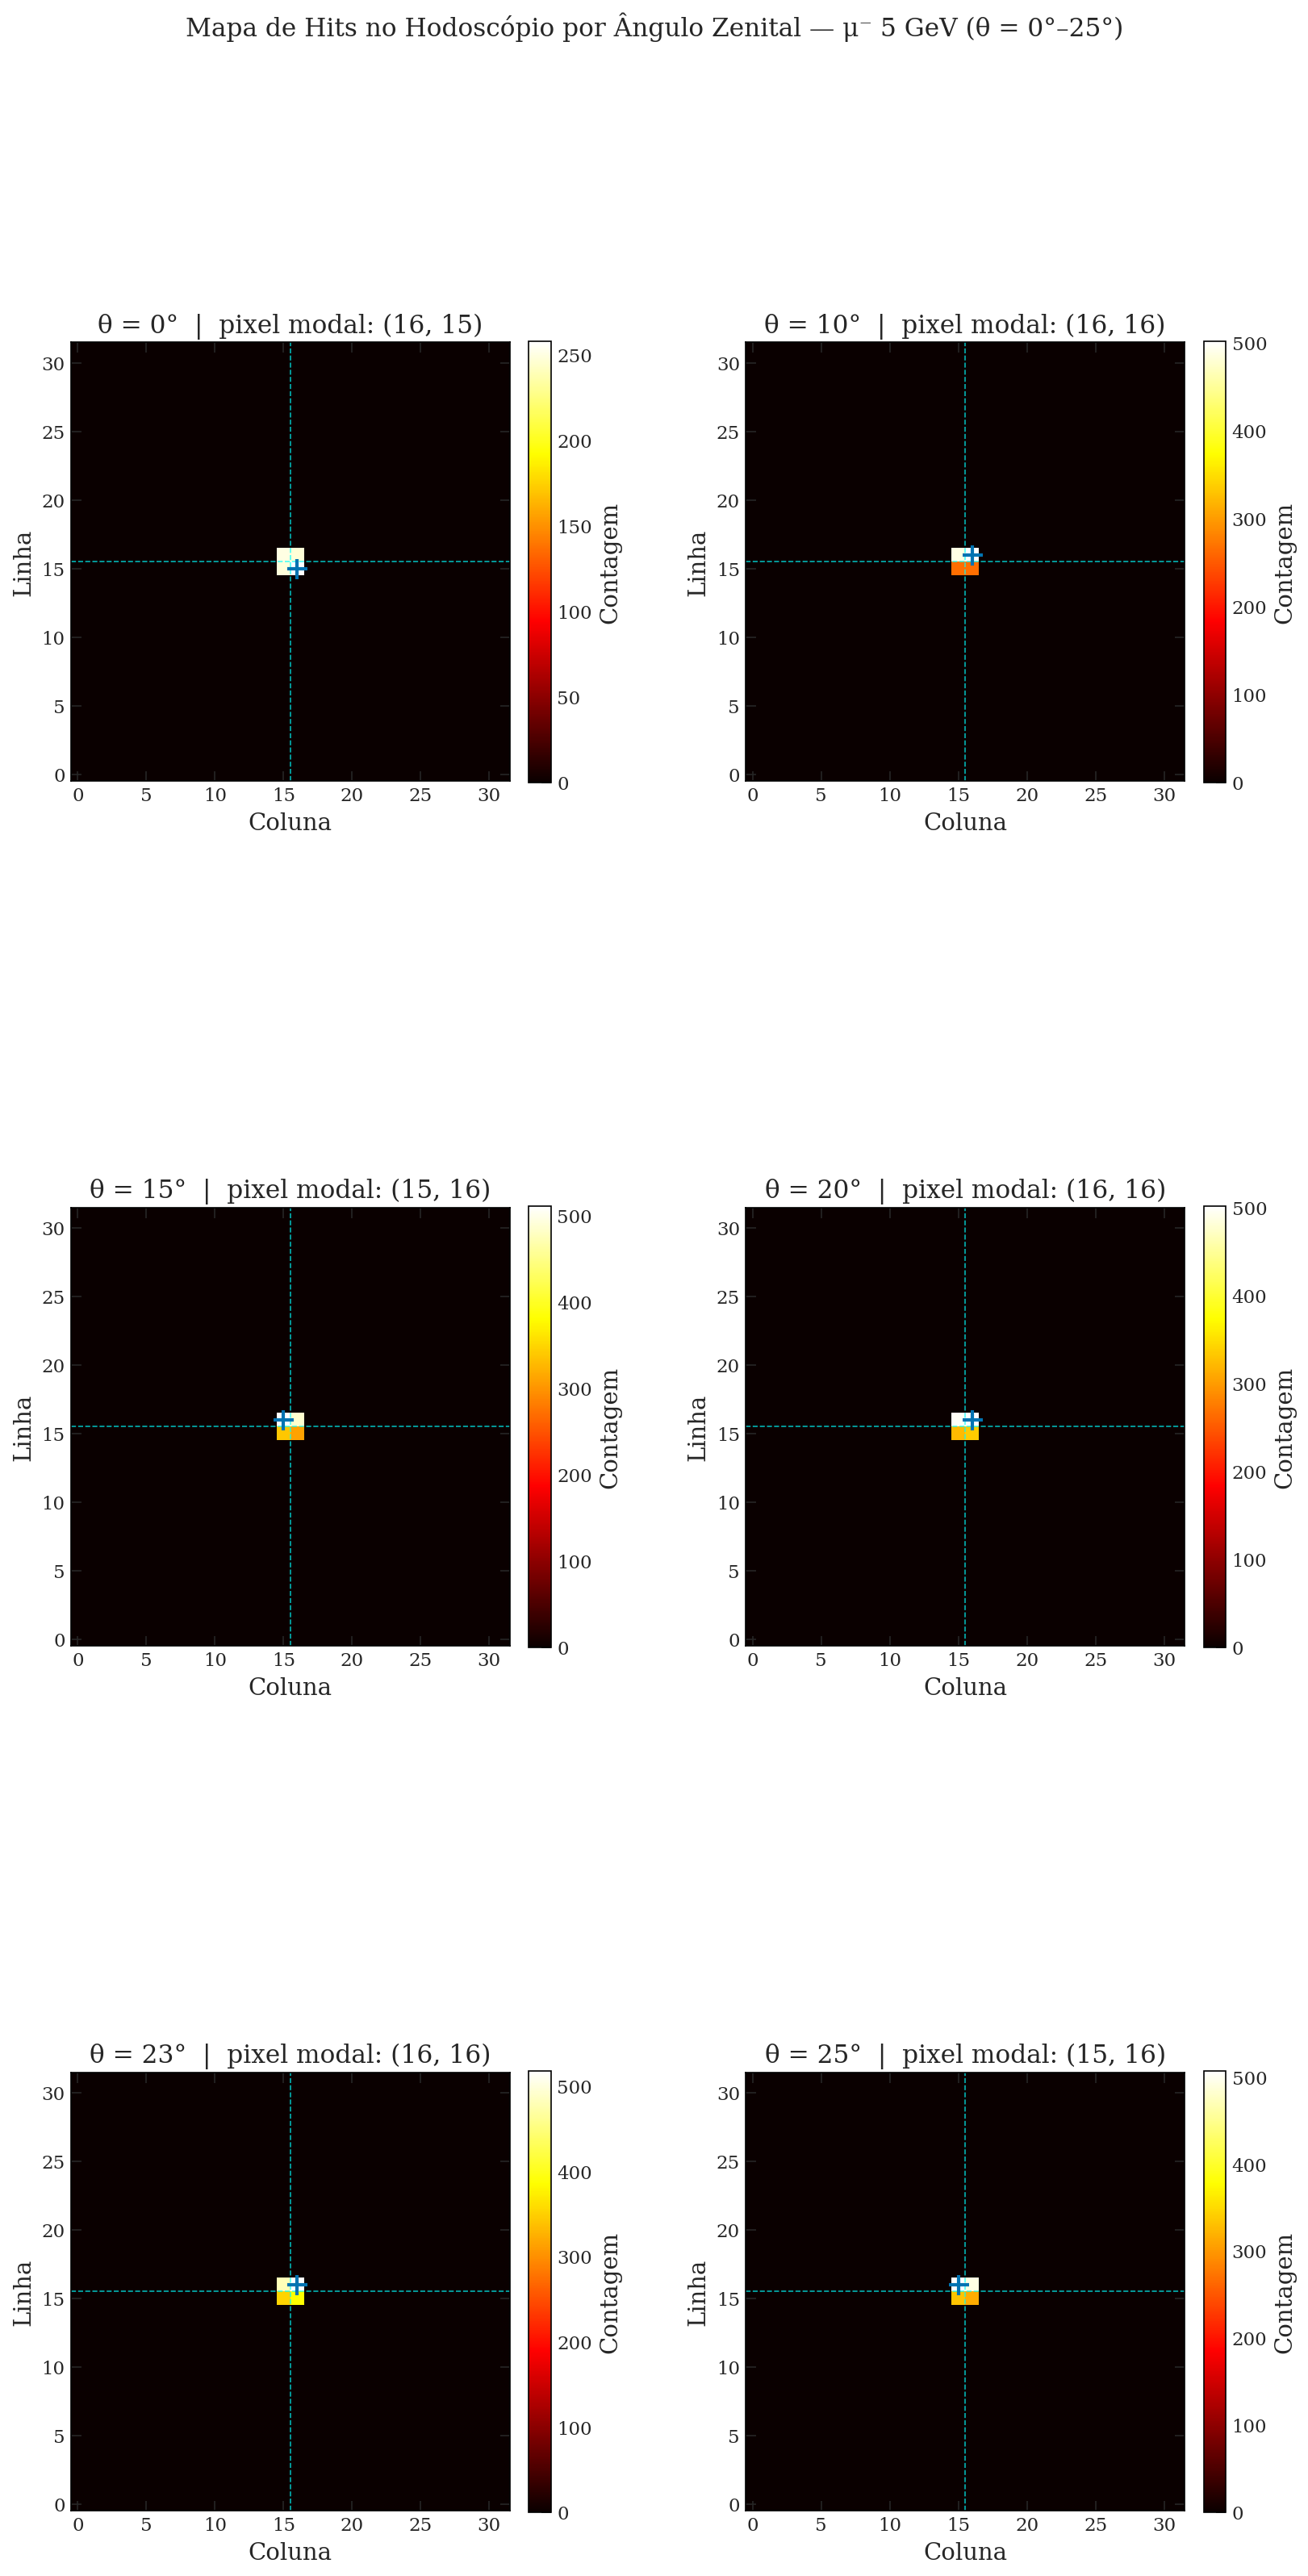

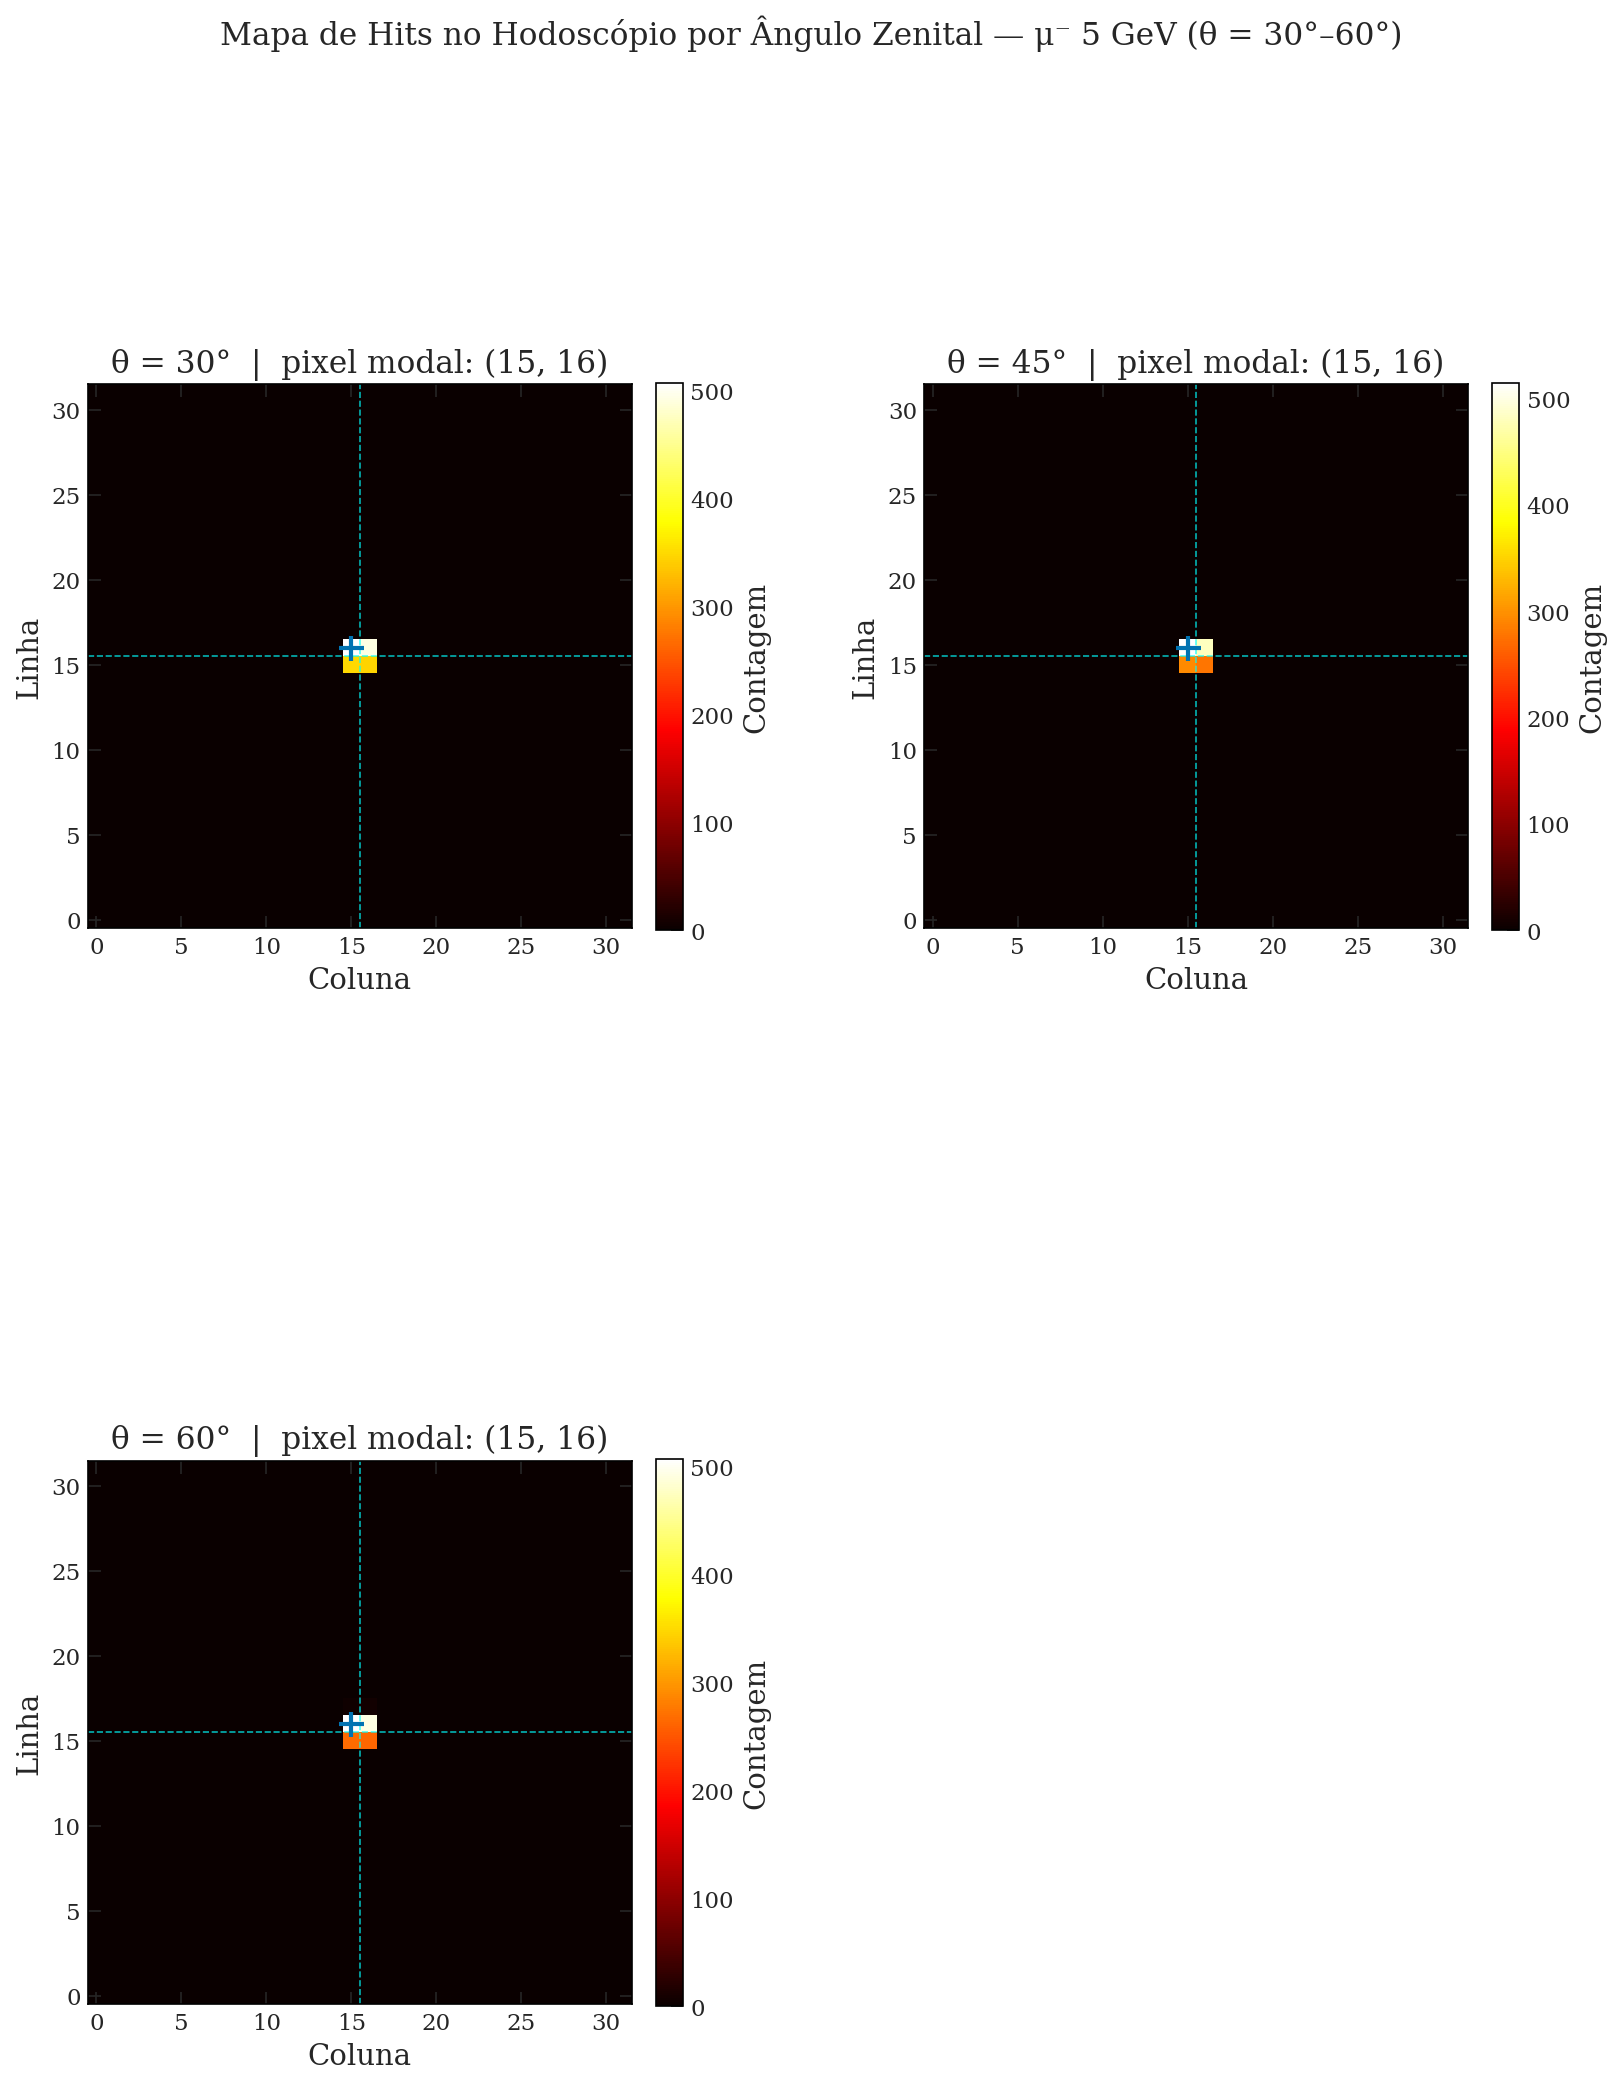


Deslocamento do hit central em relação ao píxel (15, 15):
    θ |  Col modal | Linha modal |   ΔCol |  ΔLinha
--------------------------------------------------
   0° |         16 |          15 |      1 |       0
  10° |         16 |          16 |      1 |       1
  15° |         15 |          16 |      0 |       1
  20° |         16 |          16 |      1 |       1
  23° |         16 |          16 |      1 |       1
  25° |         15 |          16 |      0 |       1
  30° |         15 |          16 |      0 |       1
  45° |         15 |          16 |      0 |       1
  60° |         15 |          16 |      0 |       1


In [10]:
def plot_hodoscopio(grupo, fname_png, suptitle_extra=''):
    n = len(grupo)
    n_rows = (n + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(11, 7.5 * n_rows))
    axes = axes.flatten()
    for i, ang in enumerate(grupo):
        ax = axes[i]
        df_hodo = dados[ang]['df_hodo']
        heatmap = np.zeros((32, 32))
        for _, row in df_hodo.iterrows():
            c, r = int(row['ColumnID']), int(row['RowID'])
            if 0 <= r < 32 and 0 <= c < 32:
                heatmap[r, c] += 1
        im = ax.imshow(heatmap, cmap='hot', origin='lower')
        plt.colorbar(im, ax=ax, label='Contagem', fraction=0.046, pad=0.04)
        ax.axvline(x=15.5, color='cyan', linewidth=0.8, linestyle='--', alpha=0.7)
        ax.axhline(y=15.5, color='cyan', linewidth=0.8, linestyle='--', alpha=0.7)
        col_mode = df_hodo['ColumnID'].mode()[0]
        row_mode = df_hodo['RowID'].mode()[0]
        ax.plot(col_mode, row_mode, 'b+', markersize=12, markeredgewidth=2)
        ax.set_xlabel('Coluna')
        ax.set_ylabel('Linha')
        ax.set_title(f'θ = {ang}°  |  pixel modal: ({col_mode}, {row_mode})')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Mapa de Hits no Hodoscópio por Ângulo Zenital — μ⁻ 5 GeV{suptitle_extra}',
                 fontsize=15, y=1.01)
    plt.tight_layout(h_pad=3, w_pad=3)
    plt.savefig(fname_png, dpi=300, bbox_inches='tight')
    plt.show()

plot_hodoscopio(grupo1, 'angular_hodoscopio_1.png', ' (θ = 0°–25°)')
plot_hodoscopio(grupo2, 'angular_hodoscopio_2.png', ' (θ = 30°–60°)')

print('\nDeslocamento do hit central em relação ao píxel (15, 15):')
print(f'{"θ":>5} | {"Col modal":>10} | {"Linha modal":>11} | {"ΔCol":>6} | {"ΔLinha":>7}')
print('-' * 50)
for ang in sorted(dados.keys()):
    dh = dados[ang]['df_hodo']
    cm = dh['ColumnID'].mode()[0]
    rm = dh['RowID'].mode()[0]
    print(f'{ang:>4}° | {cm:>10} | {rm:>11} | {cm-15:>6} | {rm-15:>7}')


## 10. Normalização pelo Comprimento do Trajeto

Verificamos se a energia por centímetro de trajeto (dE/dx) é constante — conforme esperado para MIP.

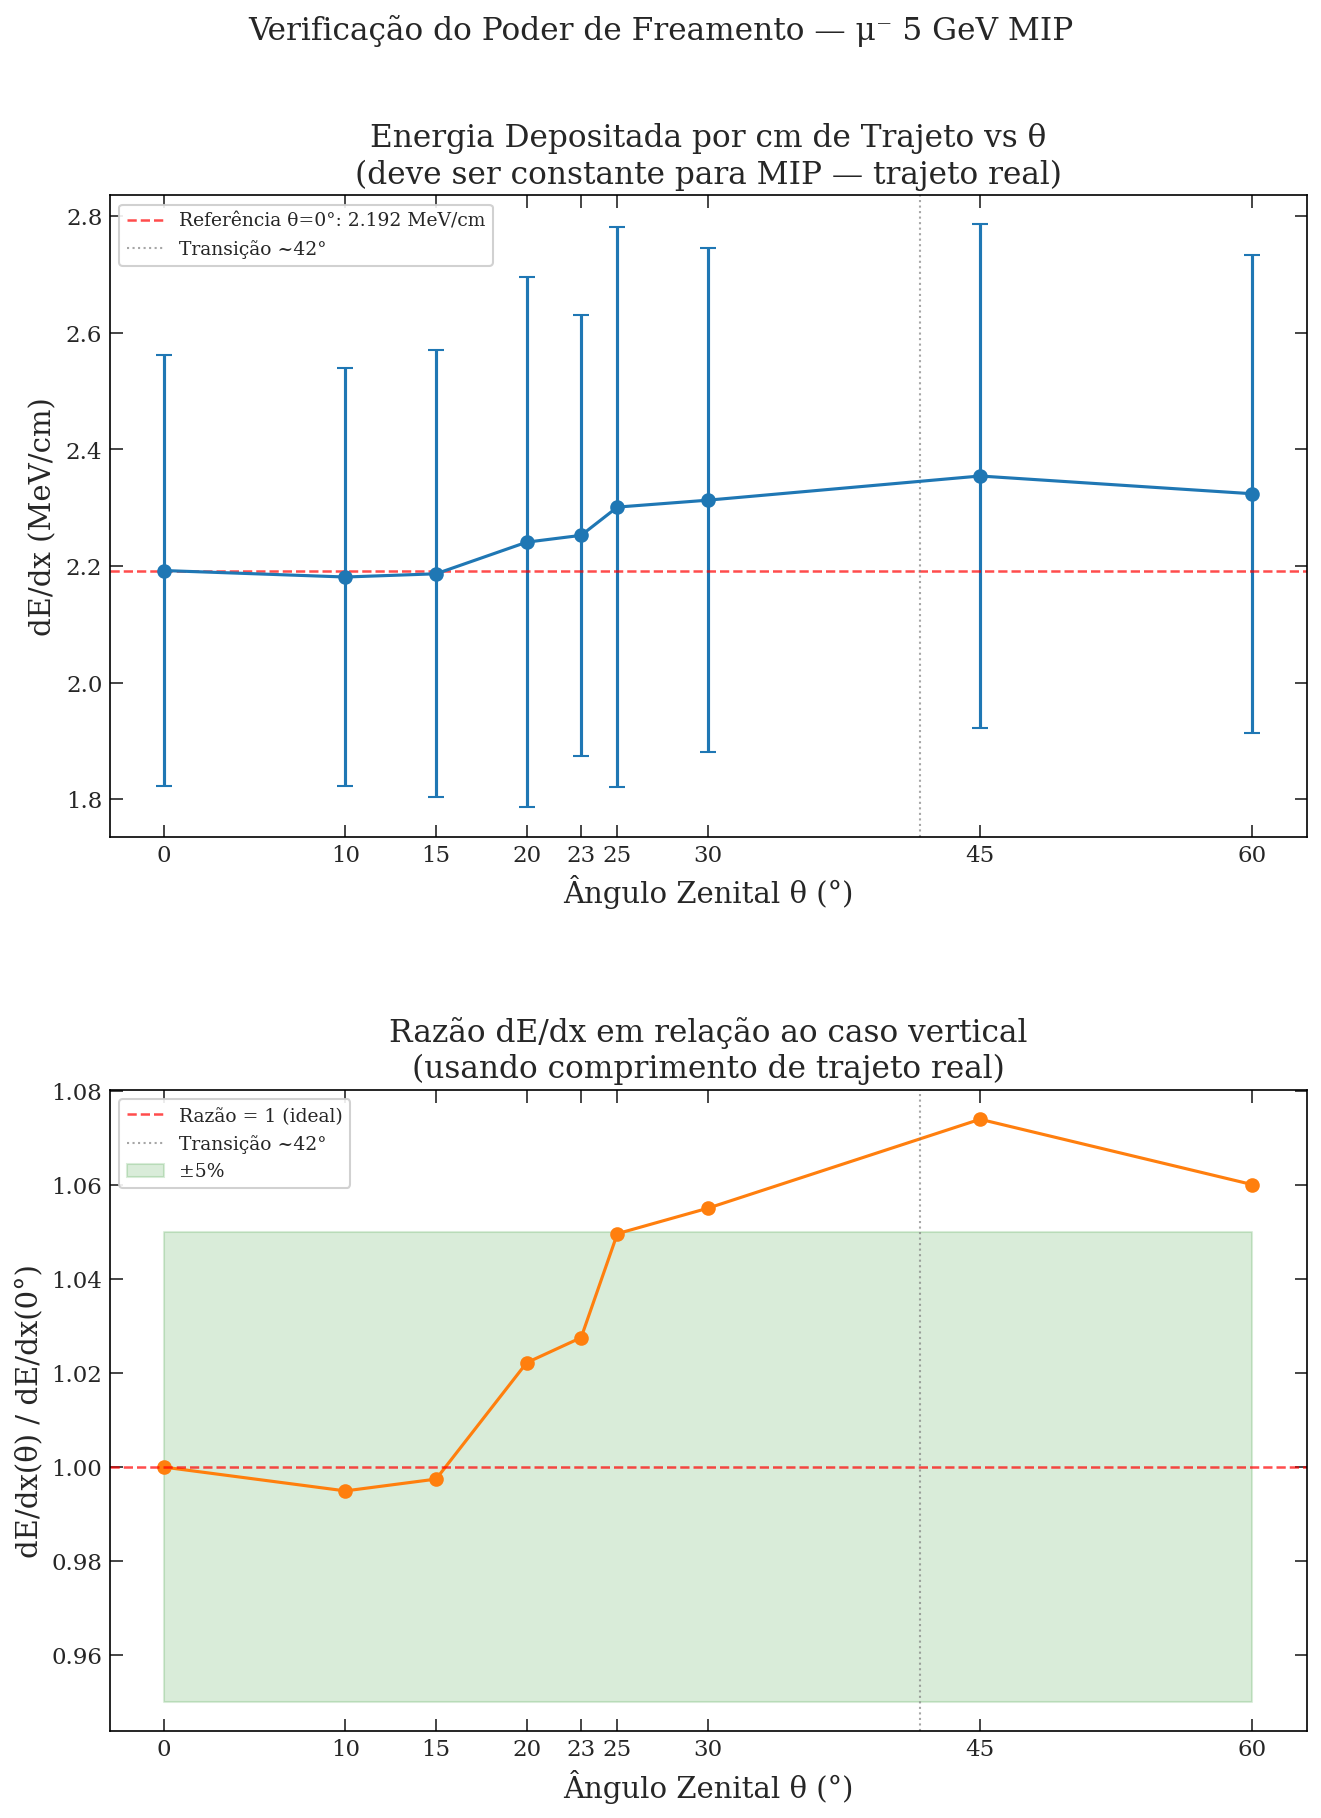


dE/dx por ângulo (trajeto real):
  θ =  0°:  L = 187.9 cm  |  dE/dx = 2.1922 ± 0.3702 MeV/cm
  θ = 10°:  L = 190.8 cm  |  dE/dx = 2.1811 ± 0.3578 MeV/cm
  θ = 15°:  L = 194.5 cm  |  dE/dx = 2.1866 ± 0.3832 MeV/cm
  θ = 20°:  L = 199.9 cm  |  dE/dx = 2.2409 ± 0.4551 MeV/cm
  θ = 23°:  L = 204.1 cm  |  dE/dx = 2.2526 ± 0.3778 MeV/cm
  θ = 25°:  L = 207.3 cm  |  dE/dx = 2.3011 ± 0.4804 MeV/cm
  θ = 30°:  L = 216.9 cm  |  dE/dx = 2.3130 ± 0.4327 MeV/cm
  θ = 45°:  L = 236.1 cm  |  dE/dx = 2.3544 ± 0.4315 MeV/cm
  θ = 60°:  L = 190.2 cm  |  dE/dx = 2.3240 ± 0.4096 MeV/cm


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(9, 12))

edep_norm_means = []
edep_norm_stds  = []

for ang in angulos_list:
    L = caminho_por_angulo(ang)   # trajeto real corrigido
    edep_por_cm = dados[ang]['df']['EnergyDeposited_MeV'] / L
    edep_norm_means.append(edep_por_cm.mean())
    edep_norm_stds.append(edep_por_cm.std())

# Plot dE/dx por ângulo
ax1 = axes[0]
ax1.errorbar(angulos_list, edep_norm_means, yerr=edep_norm_stds,
             fmt='o-', color=palette[0], capsize=4, linewidth=1.5, markersize=6)
ax1.axhline(y=edep_norm_means[0], color='red', linestyle='--',
            linewidth=1.2, alpha=0.7,
            label=f'Referência θ=0°: {edep_norm_means[0]:.3f} MeV/cm')
ax1.axvline(x=theta_trans, color='gray', linestyle=':', linewidth=1,
            alpha=0.7, label=f'Transição ~{theta_trans:.0f}°')
ax1.set_xlabel('Ângulo Zenital θ (°)')
ax1.set_ylabel('dE/dx (MeV/cm)')
ax1.set_title('Energia Depositada por cm de Trajeto vs θ\n(deve ser constante para MIP — trajeto real)')
ax1.set_xticks(angulos_list)
ax1.legend(fontsize=9)

# Razão em relação ao valor vertical
ax2 = axes[1]
razao = [m / edep_norm_means[0] for m in edep_norm_means]
ax2.plot(angulos_list, razao, 'o-', color=palette[1], linewidth=1.5, markersize=6)
ax2.axhline(y=1.0, color='red', linestyle='--', linewidth=1.2, alpha=0.7,
            label='Razão = 1 (ideal)')
ax2.fill_between(angulos_list, 0.95, 1.05, alpha=0.15, color='green', label='±5%')
ax2.axvline(x=theta_trans, color='gray', linestyle=':', linewidth=1,
            alpha=0.7, label=f'Transição ~{theta_trans:.0f}°')
ax2.set_xlabel('Ângulo Zenital θ (°)')
ax2.set_ylabel('dE/dx(θ) / dE/dx(0°)')
ax2.set_title('Razão dE/dx em relação ao caso vertical\n(usando comprimento de trajeto real)')
ax2.set_xticks(angulos_list)
ax2.legend(fontsize=9)

plt.suptitle('Verificação do Poder de Freamento — μ⁻ 5 GeV MIP', fontsize=15, y=1.01)
plt.tight_layout(h_pad=4)
plt.savefig('angular_dedx.png', dpi=300, bbox_inches='tight')
plt.show()

print('\ndE/dx por ângulo (trajeto real):')
for ang, m, s in zip(angulos_list, edep_norm_means, edep_norm_stds):
    L = caminho_por_angulo(ang)
    print(f'  θ = {ang:2d}°:  L = {L:.1f} cm  |  dE/dx = {m:.4f} ± {s:.4f} MeV/cm')


## 11. Assimetria das PMTs por Ângulo

Para o múon vertical central, as três PMTs de fundo devem responder de forma simétrica.
Com inclinação, a assimetria aumenta — um múon inclinado ilumina as PMTs de forma diferente
dependendo da direção azimutal. Este plot é essencial para verificar ângulos grandes.

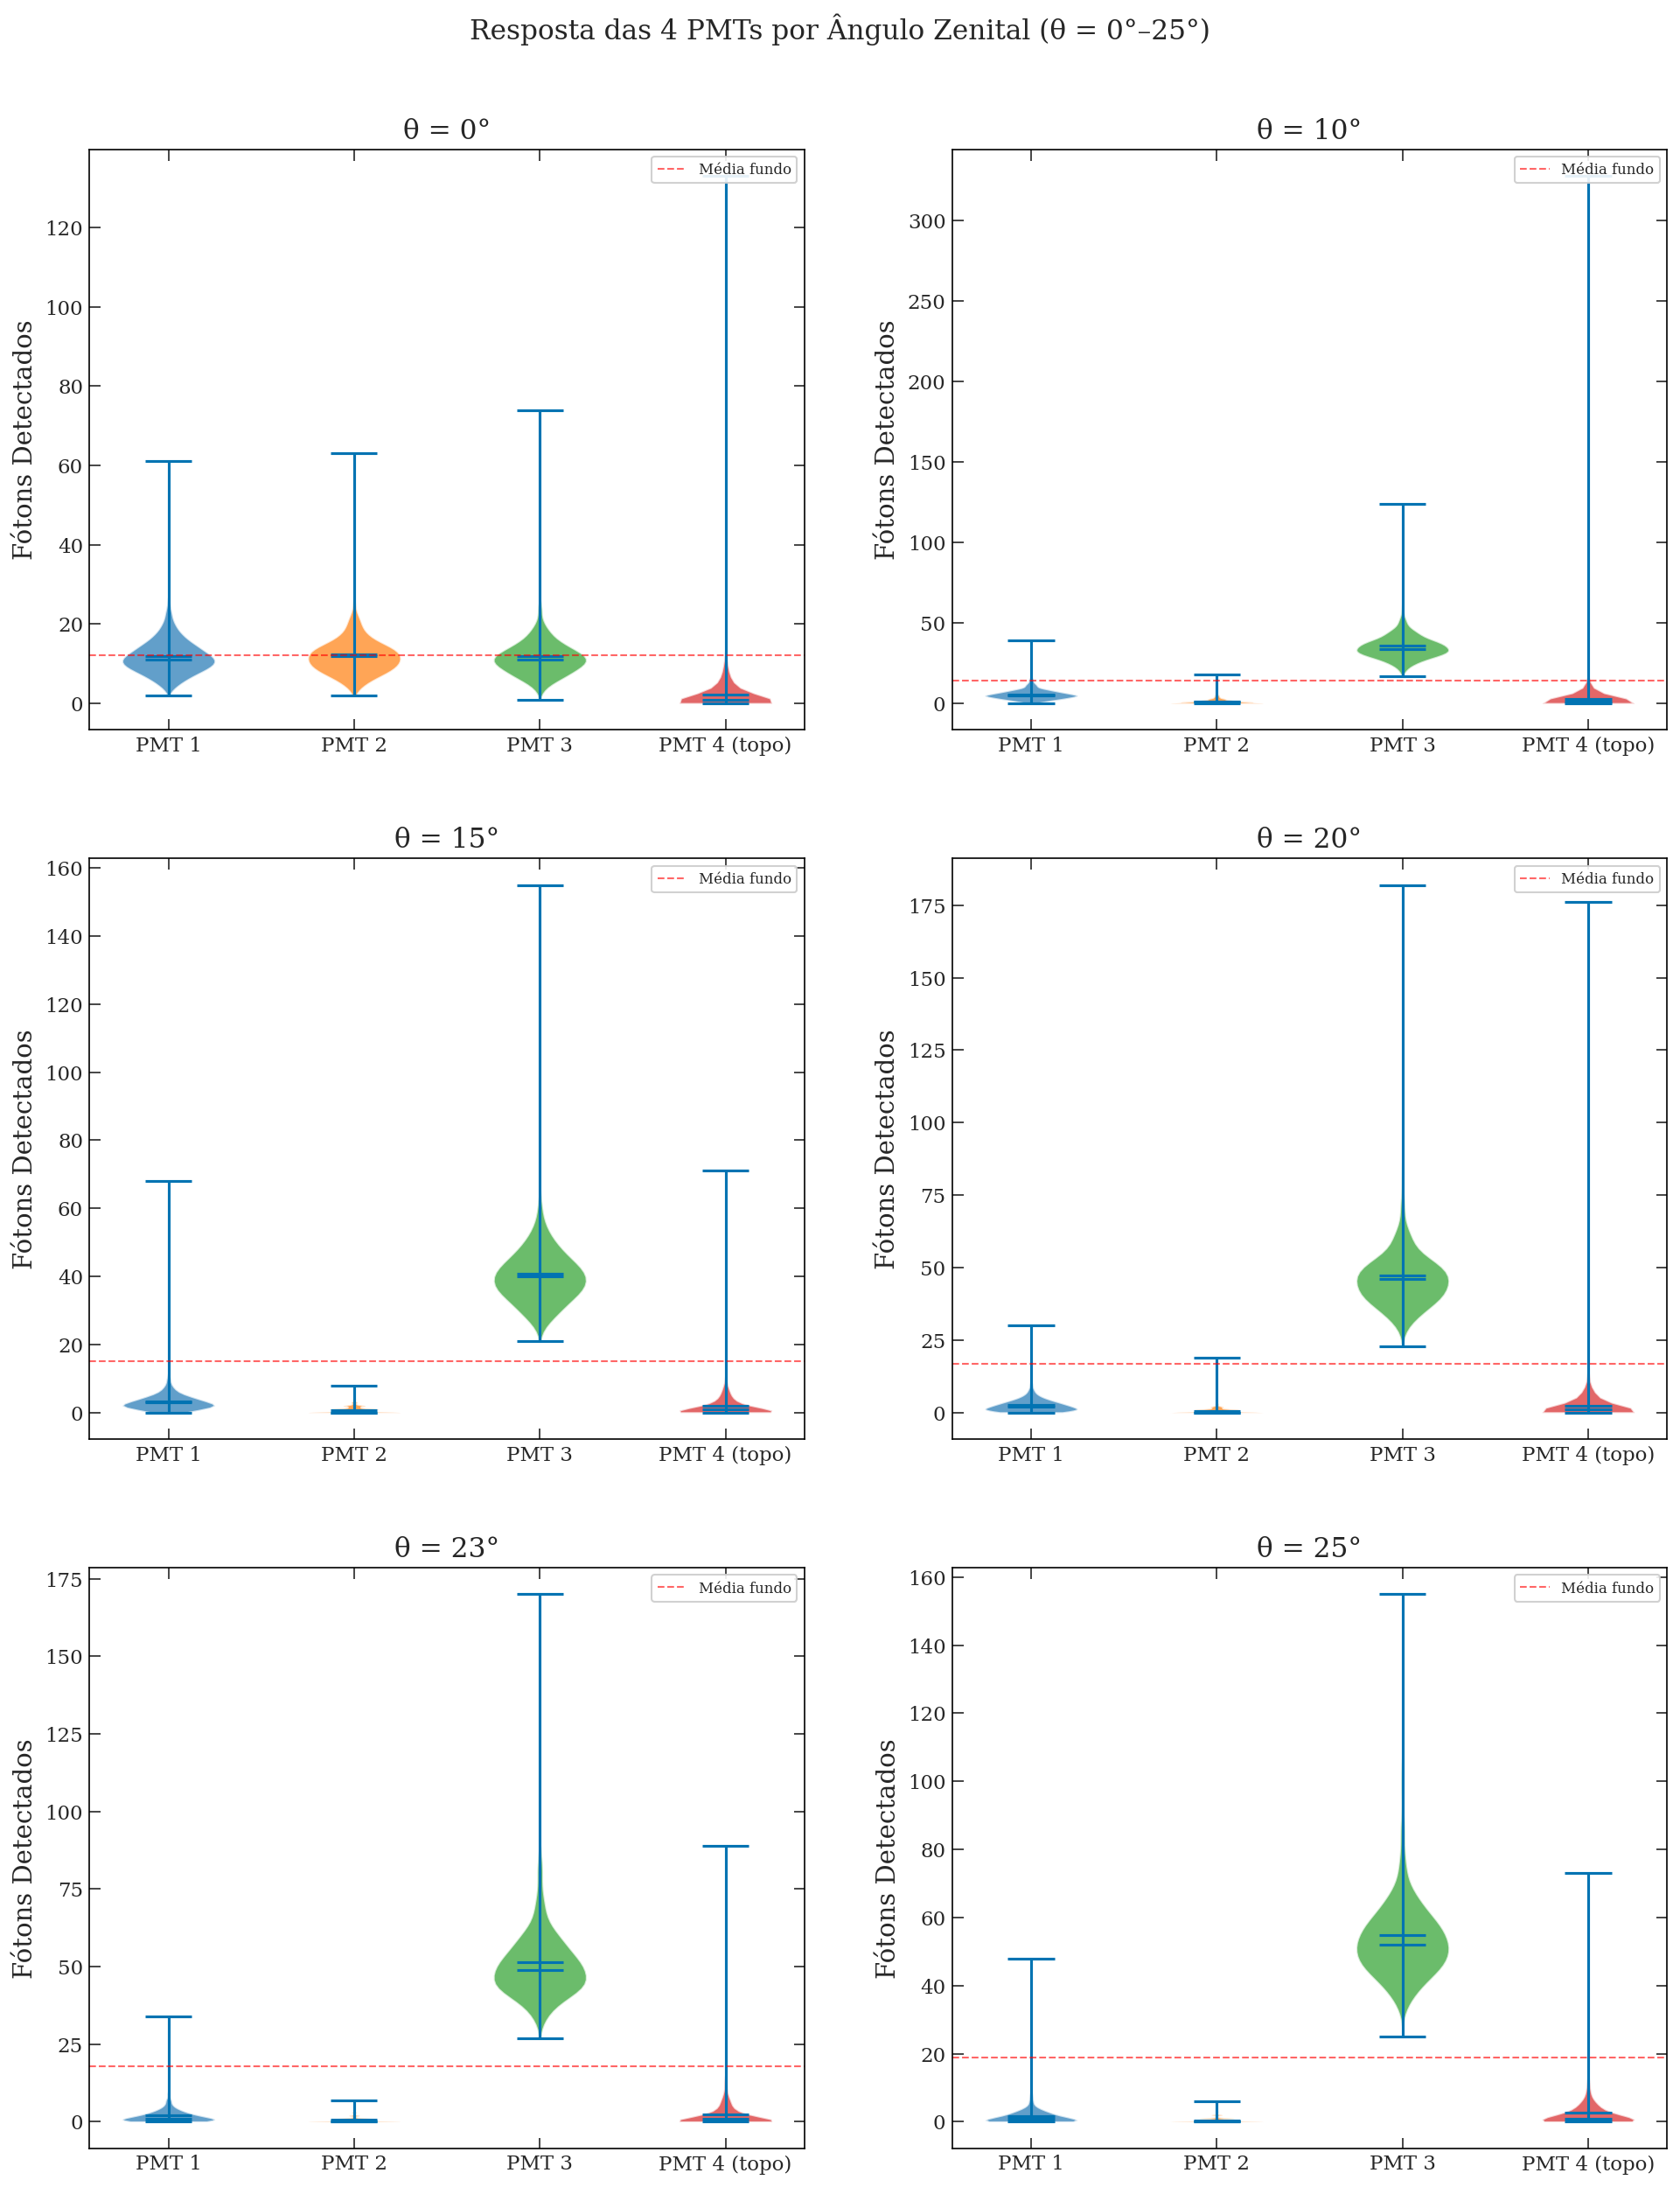

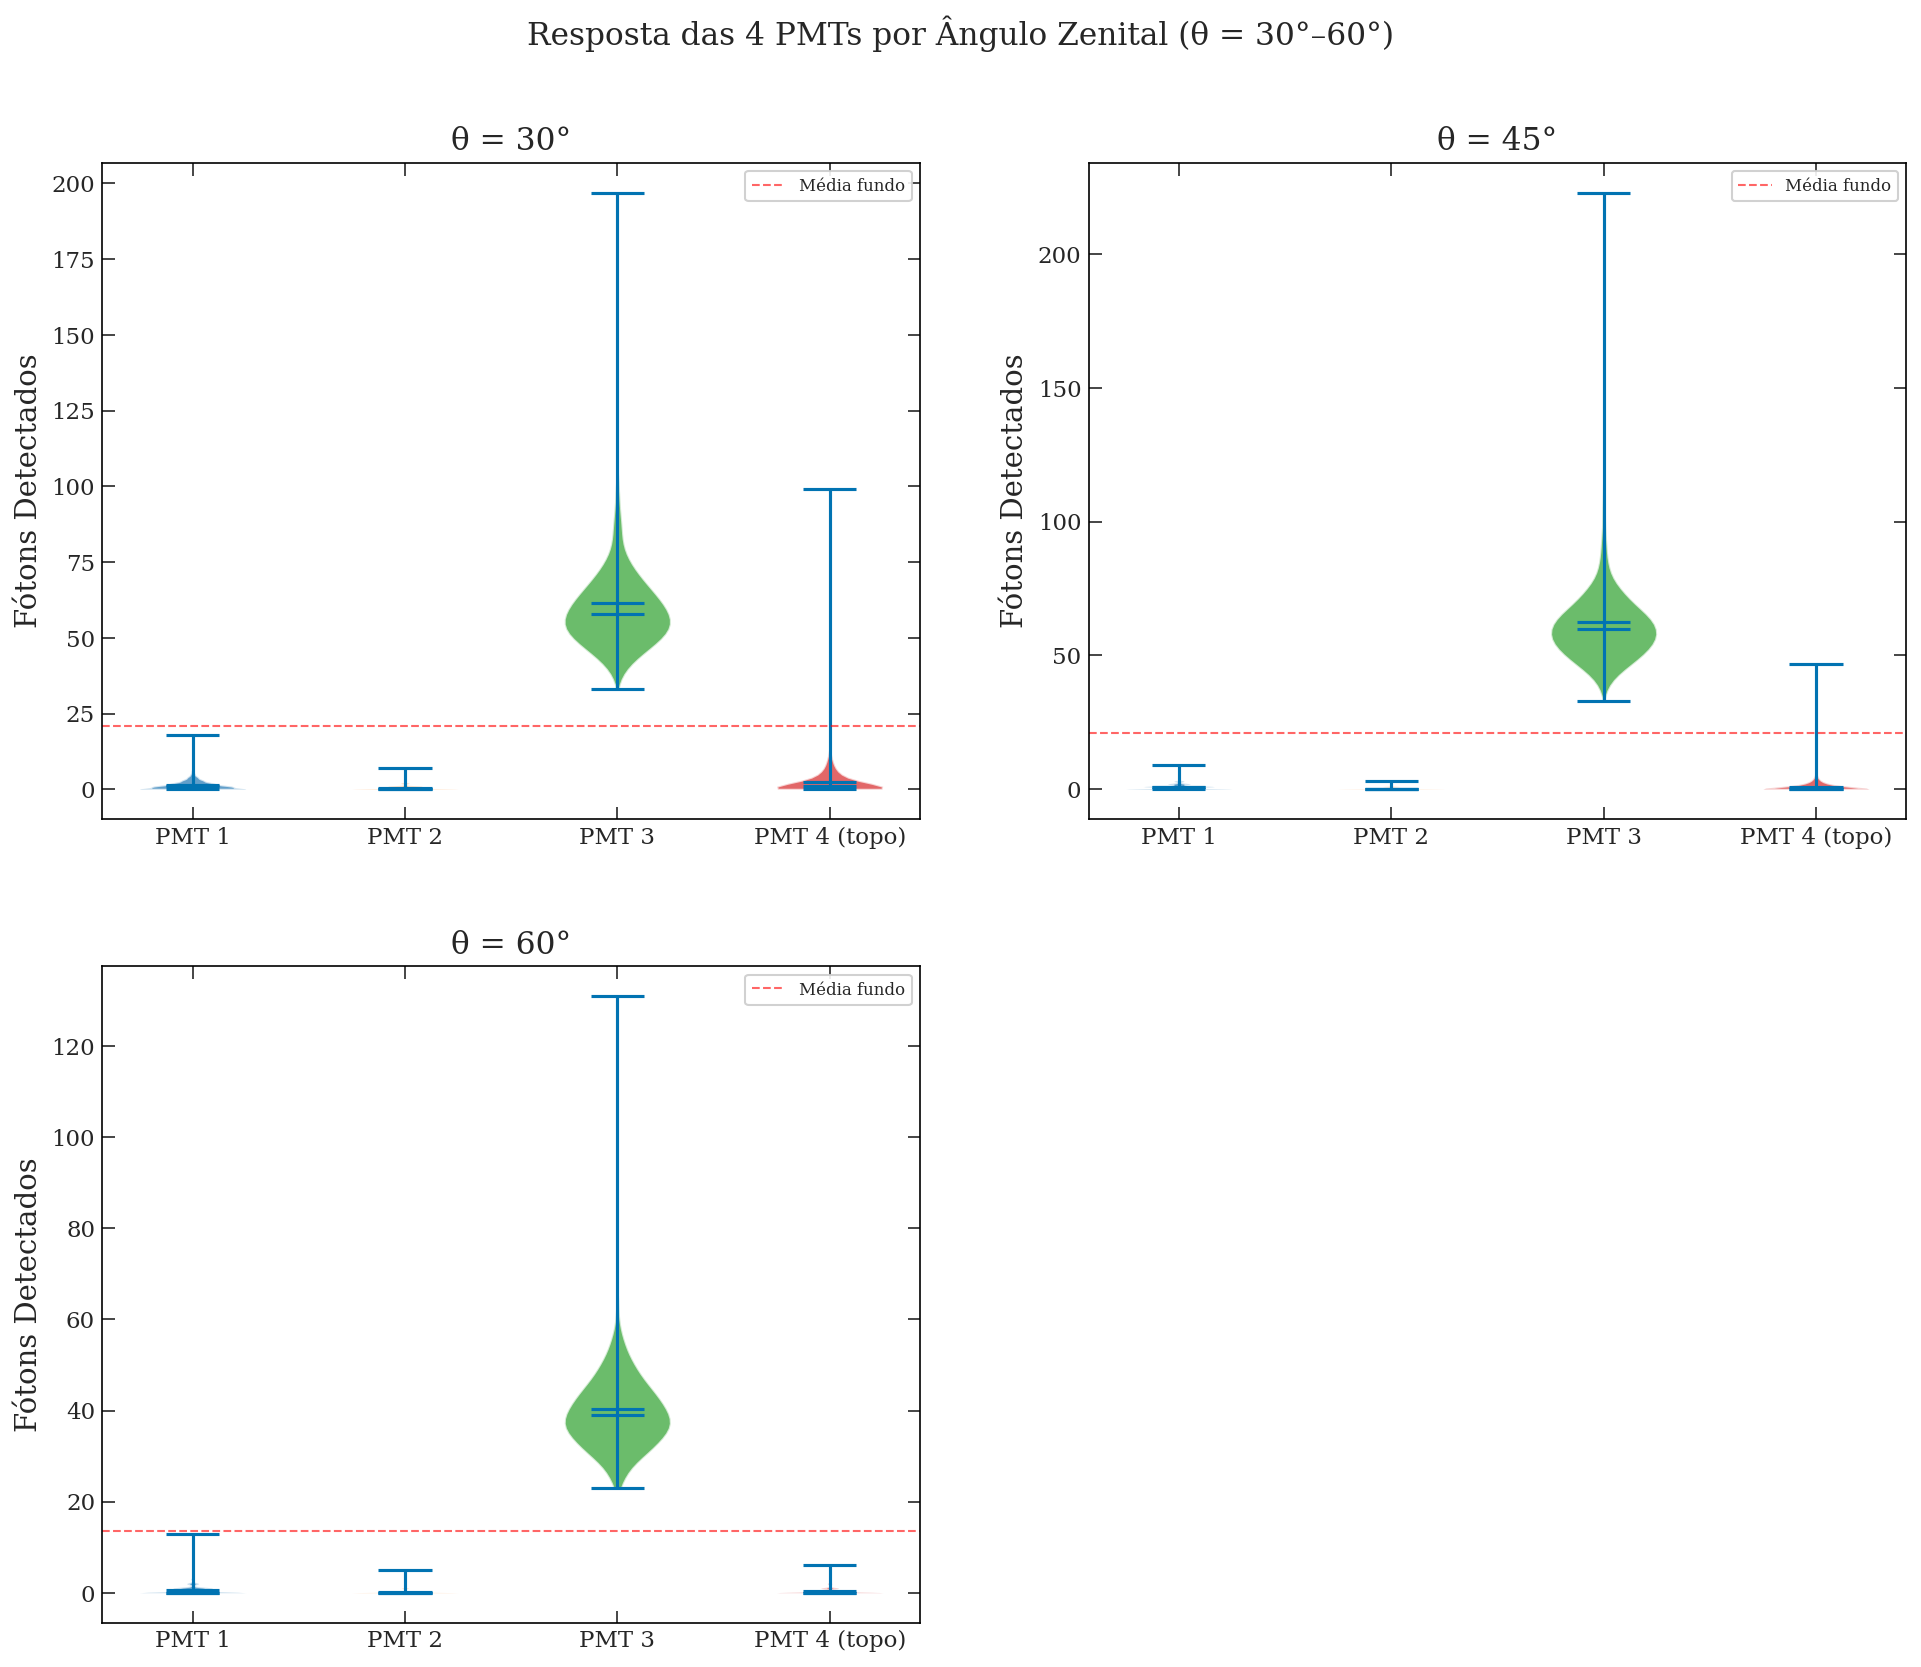

In [12]:
def plot_violin(grupo, fname_png, suptitle_extra=''):
    n = len(grupo)
    n_rows = (n + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(13, 5.5 * n_rows))
    axes = axes.flatten()
    for i, ang in enumerate(grupo):
        ax = axes[i]
        df_pmt = dados[ang]['df_pmt']
        data_v = [df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'],
                  df_pmt['nFotonsPMT3'], df_pmt['nFotonsPMT4']]
        vp = ax.violinplot(data_v, positions=[1, 2, 3, 4], showmeans=True, showmedians=True)
        cores_pmts = [palette[0], palette[1], palette[2], palette[3]]
        for j, pc in enumerate(vp['bodies']):
            pc.set_facecolor(cores_pmts[j])
            pc.set_alpha(0.7)
        ax.set_xticks([1, 2, 3, 4])
        ax.set_xticklabels(['PMT 1', 'PMT 2', 'PMT 3', 'PMT 4 (topo)'])
        ax.set_ylabel('Fótons Detectados')
        ax.set_title(f'θ = {ang}°')
        media_fundo = df_pmt[['nFotonsPMT1','nFotonsPMT2','nFotonsPMT3']].values.mean()
        ax.axhline(media_fundo, color='red', linestyle='--', linewidth=1,
                   alpha=0.6, label='Média fundo')
        ax.legend(fontsize=8)
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Resposta das 4 PMTs por Ângulo Zenital{suptitle_extra}',
                 fontsize=15, y=1.01)
    plt.tight_layout(h_pad=3, w_pad=3)
    plt.savefig(fname_png, dpi=300, bbox_inches='tight')
    plt.show()

plot_violin(grupo1, 'angular_assimetria_pmts_1.png', ' (θ = 0°–25°)')
plot_violin(grupo2, 'angular_assimetria_pmts_2.png', ' (θ = 30°–60°)')


## 12. Resumo Quantitativo da Análise Angular

In [13]:
print('=' * 100)
print('RESUMO QUANTITATIVO — ANÁLISE ANGULAR SWGO')
print(f'Partícula: μ⁻  |  Energia: 5 GeV  |  Detector: WCD (r=170 cm, h=187.87 cm)  |  4 PMTs')
print('=' * 100)

cols = ['angulo', 'L_cm', 'edep_mean', 'edep_std', 'cer_mean', 'total_mean', 'pmt4_mean', 'ef_mean']
labels = ['θ (°)', 'L (cm)', 'Edep média (MeV)', 'Edep std', 'Cer. total', 'PMTs total', 'PMT4', 'Efic. (%)']
df_print = df_resumo[cols].copy()
df_print.columns = labels
df_print = df_print.round(2)
print(df_print.to_string(index=False))
print('=' * 100)

# Variação em relação ao caso vertical
if 0 in df_resumo['angulo'].values:
    ref = df_resumo[df_resumo['angulo'] == 0].iloc[0]
    print('\nVariação relativa em relação ao caso vertical (θ = 0°):')
    print(f'{"θ":>5} | {"ΔEdep (%)": >12} | {"ΔCerenkov (%)": >14} | {"ΔPMT total (%)": >15} | {"ΔPMT4 (%)": >10} | {"ΔEfic. (pp)":>12}')
    print('-' * 75)
    for _, row in df_resumo.iterrows():
        if row['angulo'] == 0:
            continue
        delta_edep = (row['edep_mean'] - ref['edep_mean']) / ref['edep_mean'] * 100
        delta_cer  = (row['cer_mean']  - ref['cer_mean'])  / ref['cer_mean']  * 100
        delta_pmt  = (row['total_mean']- ref['total_mean'])/ ref['total_mean']* 100
        delta_pmt4 = (row['pmt4_mean'] - ref['pmt4_mean']) / ref['pmt4_mean'] * 100
        delta_ef   = row['ef_mean'] - ref['ef_mean']
        print(f'{row["angulo"]:>4}° | {delta_edep:>+11.1f}% | {delta_cer:>+13.1f}% | {delta_pmt:>+14.1f}% | {delta_pmt4:>+9.1f}% | {delta_ef:>+11.2f} pp')


RESUMO QUANTITATIVO — ANÁLISE ANGULAR SWGO
Partícula: μ⁻  |  Energia: 5 GeV  |  Detector: WCD (r=170 cm, h=187.87 cm)  |  4 PMTs
 θ (°)  L (cm)  Edep média (MeV)  Edep std  Cer. total  PMTs total  PMT4  Efic. (%)
     0  187.87            411.85     69.54    74968.05       38.54  2.28       0.05
    10  190.77            416.09     68.26    76133.69       45.46  2.84       0.06
    15  194.50            425.29     74.53    77894.95       46.92  1.98       0.06
    20  199.93            448.02     90.98    81146.53       53.01  2.44       0.06
    23  204.09            459.74     77.11    83495.75       56.14  2.29       0.07
    25  207.29            476.99     99.58    85864.18       59.52  2.57       0.07
    30  216.93            501.76     93.86    90470.37       65.58  2.49       0.07
    45  236.08            555.83    101.87   100402.63       64.40  0.99       0.06
    60  190.17            441.94     77.89    80536.21       41.28  0.28       0.05

Variação relativa em relação a

---
**Fim da análise angular.** 
Consulte os plots salvos: `angular_energia_depositada.png`, `angular_fotons_pmt.png`,
`angular_evolucao_grandezas.png`, `angular_sobreposicao.png`, `angular_hodoscopio.png`,
`angular_dedx.png`, `angular_assimetria_pmts.png`.